# Diagnóstico de problemas — Logística, Pagamentos e Satisfação

Integrante: Vitor Hugo Ramos Guerra

**Objetivo:** cruzar as três frentes (logística, pagamentos e satisfação) para encontrar **comportamentos problemáticos** que ajudam a explicar notas baixas, atrasos e cancelamentos — e onde eles se concentram (mês, região, seller, forma de pagamento, tipo de pedido).

**Regras do projeto aplicadas** (ver [relatório de qualidade](../../docs/relatorio-de-qualidade.md#8-regras-para-as-análises)):
- Período de **jan/2017 a ago/2018**.
- Análises de prazo e nota de entrega usam só pedidos `DELIVERED` com data de entrega.
- Avaliação = **última avaliação de cada pedido** (mesmo critério da Frente 4).
- `payments` e `order_items` são agregados por pedido antes do join.
- Clientes contados por `customer_unique_id`.

**Importante:** as comparações são descritivas. Elas mostram onde os problemas se concentram, mas não provam causa.

In [1]:
%run ../../src/librarys.ipynb

In [2]:
# Padrão visual
AZUL = '#2a78d6'      # série principal
LARANJA = '#eb6834'   # série de comparação
VERDE_AGUA = '#1baf7a'
AMARELO = '#eda100'
CINZA = '#898781'     # contexto / referência
VERMELHO = '#d03b3b'  # destaque de problema
TEXTO = '#52514e'

plt.rcParams.update({
    'figure.figsize': (10, 4.5),
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': TEXTO,
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6,
    'xtick.color': TEXTO,
    'ytick.color': TEXTO,
    'font.size': 10,
    'legend.frameon': False,
})

DATA = Path('../../data/processed')

## 1. Carregamento e base por pedido

Uma linha por pedido, com:
- **avaliação:** última avaliação registrada;
- **pagamento:** forma principal (a de maior valor), quantidade de pagamentos, maior número de parcelas e valor pago;
- **itens:** quantidade de itens, quantidade de sellers, prazo de postagem do seller e seller principal (item de maior preço) com sua UF.

In [3]:
datas = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
         'order_delivered_customer_date', 'order_estimated_delivery_date']

orders = pd.read_csv(DATA / 'orders_enriched.csv', parse_dates=datas)
items = pd.read_csv(DATA / 'order_items_category.csv', parse_dates=['shipping_limit_date'])
payments = pd.read_csv(DATA / 'payments.csv')
reviews = pd.read_csv(DATA / 'reviews.csv', parse_dates=['review_creation_date', 'review_answer_timestamp'])
customers = pd.read_csv(DATA / 'customers.csv', dtype={'customer_zip_code_prefix': str})
sellers = pd.read_csv(DATA / 'sellers.csv', dtype={'seller_zip_code_prefix': str})

for nome, tabela in [('orders', orders), ('items', items), ('payments', payments),
                     ('reviews', reviews), ('customers', customers), ('sellers', sellers)]:
    print(f'{nome:10} {tabela.shape}')

orders     (99441, 17)
items      (112650, 14)
payments   (103886, 5)
reviews    (99224, 7)
customers  (99441, 5)
sellers    (3095, 4)


In [4]:
# Avaliação: última avaliação de cada pedido
aval = (reviews.sort_values(['review_creation_date', 'review_answer_timestamp'])
        .drop_duplicates('order_id', keep='last')
        [['order_id', 'review_score', 'review_comment_message', 'review_creation_date']])

# Pagamento: forma principal = a de maior valor no pedido
pag = (payments.sort_values('payment_value', ascending=False)
       .groupby('order_id')
       .agg(forma_pagamento=('payment_type', 'first'),
            qtd_pagamentos=('payment_sequential', 'count'),
            parcelas=('payment_installments', 'max'),
            valor_pago=('payment_value', 'sum'),
            usou_voucher=('payment_type', lambda s: s.eq('VOUCHER').any()))
       .reset_index())

# Itens: seller principal = seller do item de maior preço
itens = (items.sort_values('price', ascending=False)
         .groupby('order_id')
         .agg(qtd_itens=('order_item_id', 'count'),
              qtd_sellers=('seller_id', 'nunique'),
              prazo_postagem=('shipping_limit_date', 'max'),
              seller_id=('seller_id', 'first'),
              categoria=('product_category_name', 'first'))
         .reset_index()
         .merge(sellers[['seller_id', 'seller_state']], on='seller_id', how='left'))

base = (orders.drop(columns='review_score')
        .merge(aval, on='order_id', how='left')
        .merge(pag, on='order_id', how='left')
        .merge(itens, on='order_id', how='left')
        .merge(customers[['customer_id', 'customer_unique_id']], on='customer_id', how='left'))

assert base['order_id'].is_unique, 'join multiplicou pedidos'

base = base[(base['order_purchase_timestamp'] >= '2017-01-01') &
            (base['order_purchase_timestamp'] < '2018-09-01')].copy()
print('Pedidos no período:', f'{len(base):,}')

Pedidos no período: 99,092


In [5]:
def dias(inicio, fim):
    return (base[fim] - base[inicio]).dt.total_seconds() / 86400

base['dias_aprovacao'] = dias('order_purchase_timestamp', 'order_approved_at')
base['dias_postagem'] = dias('order_approved_at', 'order_delivered_carrier_date')
base['dias_transporte'] = dias('order_delivered_carrier_date', 'order_delivered_customer_date')
base['dias_total'] = dias('order_purchase_timestamp', 'order_delivered_customer_date')
base['dias_prometidos'] = dias('order_purchase_timestamp', 'order_estimated_delivery_date')
base['folga'] = base['dias_prometidos'] - base['dias_total']  # positivo = chegou antes do prometido

base['seller_postou_atrasado'] = base['order_delivered_carrier_date'] > base['prazo_postagem']
base['mesma_uf'] = base['seller_state'] == base['customer_state']
base['nota_baixa'] = base['review_score'] <= 2
base['cancelado'] = base['order_status'].isin(['CANCELED', 'UNAVAILABLE'])

REGIAO = {
    'AC': 'Norte', 'AM': 'Norte', 'AP': 'Norte', 'PA': 'Norte', 'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste', 'MA': 'Nordeste', 'PB': 'Nordeste',
    'PE': 'Nordeste', 'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'MT': 'Centro-Oeste',
    'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul',
}
base['regiao'] = base['customer_state'].map(REGIAO)

# Pedidos entregues: base das análises de prazo
entregues = base[(base['order_status'] == 'DELIVERED') & base['order_delivered_customer_date'].notna()].copy()

# Para o lead time por etapa, descartamos datas fora de ordem (ver relatório de qualidade)
cronologia_ok = (
    (entregues['order_approved_at'] >= entregues['order_purchase_timestamp']) &
    (entregues['order_delivered_carrier_date'] >= entregues['order_approved_at']) &
    (entregues['order_delivered_customer_date'] >= entregues['order_delivered_carrier_date'])
)
etapas = entregues[cronologia_ok]

print('Pedidos entregues:', f'{len(entregues):,}')
print('Entregues com cronologia válida:', f'{len(etapas):,}', f'({len(etapas) / len(entregues):.1%})')
print('Taxa de atraso geral:', f"{entregues['is_late'].mean():.1%}")

Pedidos entregues: 96,203
Entregues com cronologia válida: 94,819 (98.6%)
Taxa de atraso geral: 6.8%


---
# Parte A — Logística

## 2. Onde o tempo é gasto: lead time por etapa

Usamos a **média** de cada etapa para que a soma bata com o tempo total.

,média,mediana,p90,% do tempo total
Compra → aprovação,0.40,0.01,1.39,3.18
Aprovação → postagem (seller),2.82,1.84,5.99,22.41
Postagem → entrega (transportadora),9.37,7.12,18.96,74.41


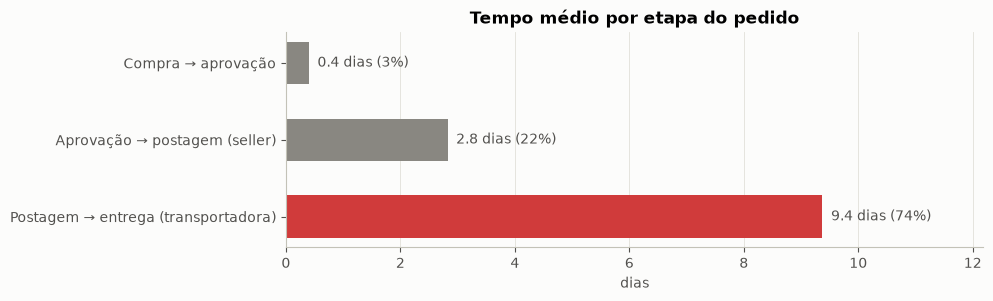

In [6]:
colunas_etapas = {'dias_aprovacao': 'Compra → aprovação',
                  'dias_postagem': 'Aprovação → postagem (seller)',
                  'dias_transporte': 'Postagem → entrega (transportadora)'}

lead = (etapas[list(colunas_etapas)]
        .agg(['mean', 'median', lambda s: s.quantile(0.9)])
        .T.rename(index=colunas_etapas, columns={'mean': 'média', 'median': 'mediana', '<lambda>': 'p90'}))
lead['% do tempo total'] = lead['média'] / lead['média'].sum() * 100
display(lead.round(2))

fig, ax = plt.subplots(figsize=(9, 2.8))
cores = [CINZA, CINZA, VERMELHO]
ax.barh(lead.index[::-1], lead['média'][::-1], color=cores[::-1], height=0.55)
for i, (valor, pct) in enumerate(zip(lead['média'][::-1], lead['% do tempo total'][::-1])):
    ax.text(valor + 0.15, i, f'{valor:.1f} dias ({pct:.0f}%)', va='center', color=TEXTO)
ax.set(title='Tempo médio por etapa do pedido', xlabel='dias')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, lead['média'].max() * 1.3)
plt.show()

### 2.1 Prazo prometido x prazo real

`folga` = dias prometidos − dias reais. Folga positiva = chegou antes do prometido; negativa = atrasou.

,count,mean,std,min,10%,50%,90%,max
dias_total,96203.0,12.5,9.5,0.5,4.2,10.2,23.1,209.6
dias_prometidos,96203.0,23.6,8.6,2.0,13.0,23.2,34.2,155.1
folga,96203.0,11.1,10.1,-189.0,1.1,11.8,21.2,146.0


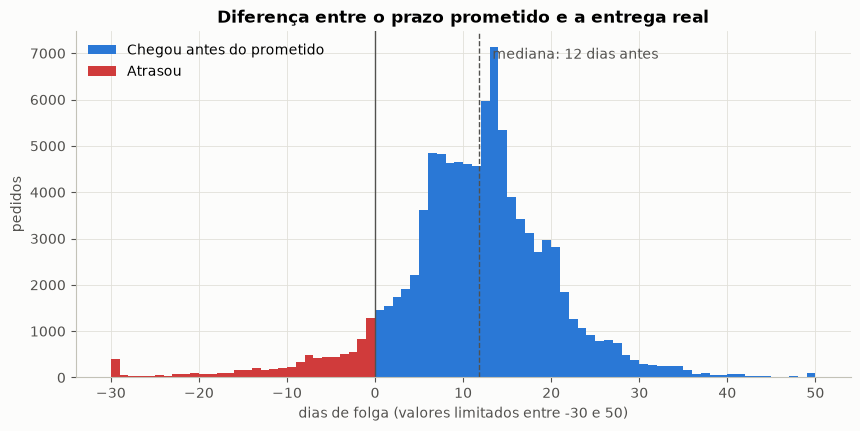

In [7]:
prazos = entregues[['dias_total', 'dias_prometidos', 'folga']].describe(percentiles=[0.1, 0.5, 0.9]).T
display(prazos.round(1))

fig, ax = plt.subplots()
folga = entregues['folga'].clip(-30, 50)
ax.hist(folga[folga >= 0], bins=np.arange(0, 51, 1), color=AZUL, label='Chegou antes do prometido')
ax.hist(folga[folga < 0], bins=np.arange(-30, 1, 1), color=VERMELHO, label='Atrasou')
ax.axvline(0, color=TEXTO, linewidth=1)
ax.axvline(entregues['folga'].median(), color=TEXTO, linewidth=1, linestyle='--')
ax.text(entregues['folga'].median() + 1.5, ax.get_ylim()[1] * 0.92,
        f"mediana: {entregues['folga'].median():.0f} dias antes", color=TEXTO)
ax.set(title='Diferença entre o prazo prometido e a entrega real',
       xlabel='dias de folga (valores limitados entre -30 e 50)', ylabel='pedidos')
ax.legend()
plt.show()

## 3. Atraso ao longo do tempo

In [8]:
mensal = entregues.groupby('purchase_year_month').agg(
    pedidos=('order_id', 'size'),
    pct_atraso=('is_late', 'mean'),
    dias_total_mediana=('dias_total', 'median'),
    dias_prometidos_mediana=('dias_prometidos', 'median'),
    nota_media=('review_score', 'mean'),
)
mensal['pct_atraso'] *= 100
display(mensal.round(2))

,pedidos,pct_atraso,dias_total_mediana,dias_prometidos_mediana,nota_media
purchase_year_month,,,,,
2017-01,750,2.93,10.73,38.98,4.20
2017-02,1653,2.96,10.97,30.18,4.20
2017-03,2546,4.56,10.13,22.59,4.19
2017-04,2303,6.56,12.75,25.47,4.14
2017-05,3545,2.99,9.79,23.34,4.24
2017-06,3135,3.03,10.80,23.42,4.22
2017-07,3872,2.79,10.16,23.01,4.26
2017-08,4193,2.91,9.77,22.55,4.31
2017-09,4150,4.39,10.31,22.14,4.27


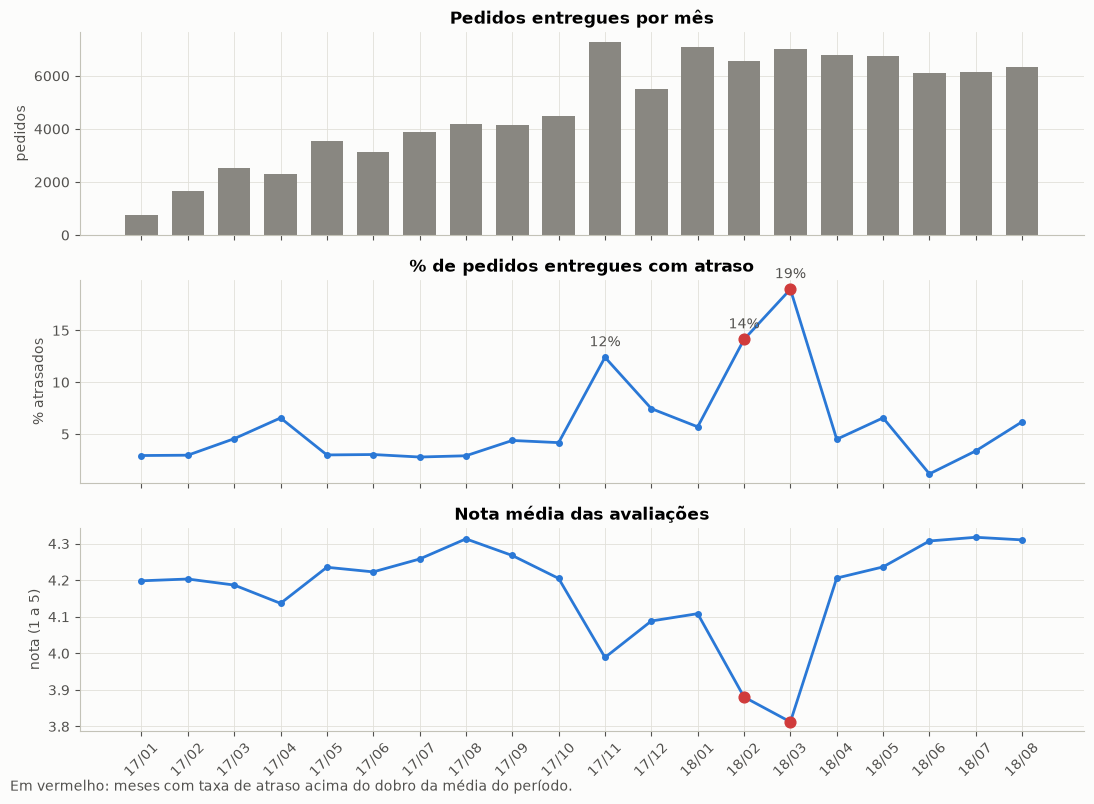

Meses em crise: 2018-02, 2018-03


In [9]:
crise = mensal['pct_atraso'] > 2 * entregues['is_late'].mean() * 100
meses = mensal.index.str[2:].str.replace('-', '/')
x = np.arange(len(mensal))

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].bar(x, mensal['pedidos'], color=CINZA, width=0.7)
axes[0].set(title='Pedidos entregues por mês', ylabel='pedidos')

axes[1].plot(x, mensal['pct_atraso'], color=AZUL, linewidth=2, marker='o', markersize=4)
axes[1].scatter(x[crise], mensal['pct_atraso'][crise], color=VERMELHO, s=60, zorder=3)
for i in x[mensal['pct_atraso'] > 10]:
    axes[1].annotate(f"{mensal['pct_atraso'].iloc[i]:.0f}%", (i, mensal['pct_atraso'].iloc[i]),
                     textcoords='offset points', xytext=(0, 8), ha='center', color=TEXTO)
axes[1].set(title='% de pedidos entregues com atraso', ylabel='% atrasados')

axes[2].plot(x, mensal['nota_media'], color=AZUL, linewidth=2, marker='o', markersize=4)
axes[2].scatter(x[crise], mensal['nota_media'][crise], color=VERMELHO, s=60, zorder=3)
axes[2].set(title='Nota média das avaliações', ylabel='nota (1 a 5)')

axes[2].set_xticks(x, meses, rotation=45)
fig.text(0.01, 0.005, 'Em vermelho: meses com taxa de atraso acima do dobro da média do período.', color=TEXTO)
plt.tight_layout()
plt.show()

print('Meses em crise:', ', '.join(mensal.index[crise]))

**Os meses de crise foram nacionais ou só de algumas regiões?** Comparamos a taxa de atraso em cada região nos meses de crise e nos demais.

In [10]:
entregues['mes_crise'] = entregues['purchase_year_month'].isin(mensal.index[crise])
crise_regiao = (entregues.pivot_table(index='regiao', columns='mes_crise', values='is_late', aggfunc='mean') * 100)
crise_regiao.columns = ['% atraso meses normais', '% atraso meses de crise']
crise_regiao['aumento (p.p.)'] = crise_regiao['% atraso meses de crise'] - crise_regiao['% atraso meses normais']
display(crise_regiao.sort_values('aumento (p.p.)', ascending=False).round(1))

,% atraso meses normais,% atraso meses de crise,aumento (p.p.)
regiao,,,
Norte,5.9,27.4,21.6
Nordeste,10.4,27.4,16.9
Centro-Oeste,4.4,18.4,13.9
Sul,4.2,15.9,11.7
Sudeste,4.7,14.9,10.2


**Atenção:** em ago/2018 só entram pedidos que já tinham sido entregues até o fim da base, o que favorece entregas rápidas. Os números desse mês tendem a parecer melhores do que foram.

## 4. Desempenho por região

Para cada UF do cliente: atraso, prazo real e prometido (medianas), folga, nota e peso do frete sobre o preço dos produtos.

In [11]:
uf = entregues.groupby('customer_state').agg(
    regiao=('regiao', 'first'),
    pedidos=('order_id', 'size'),
    pct_atraso=('is_late', 'mean'),
    dias_reais=('dias_total', 'median'),
    dias_prometidos=('dias_prometidos', 'median'),
    folga_mediana=('folga', 'median'),
    nota_media=('review_score', 'mean'),
    frete=('order_freight', 'sum'),
    preco=('order_price', 'sum'),
)
uf['pct_atraso'] *= 100
uf['frete_sobre_preco_%'] = uf['frete'] / uf['preco'] * 100
uf = uf.drop(columns=['frete', 'preco']).sort_values('pct_atraso', ascending=False)
display(uf.round(2))

,regiao,pedidos,pct_atraso,dias_reais,dias_prometidos,folga_mediana,nota_media,frete_sobre_preco_%
customer_state,,,,,,,,
AL,Nordeste,396,21.46,22.33,31.41,9.43,3.85,19.40
MA,Nordeste,713,17.53,19.18,30.18,10.00,3.83,26.22
SE,Nordeste,332,15.36,17.93,29.53,12.10,3.90,24.26
PI,Nordeste,475,13.89,16.28,29.47,13.05,3.99,24.16
CE,Nordeste,1273,13.83,18.17,31.21,12.24,3.94,21.29
RR,Norte,40,12.50,25.13,44.30,18.13,3.90,27.83
BA,Nordeste,3253,12.17,16.91,29.01,11.56,3.93,19.76
RJ,Sudeste,12310,12.14,12.04,24.59,12.25,3.97,16.84
PA,Norte,942,11.25,21.07,36.10,15.06,3.91,21.55


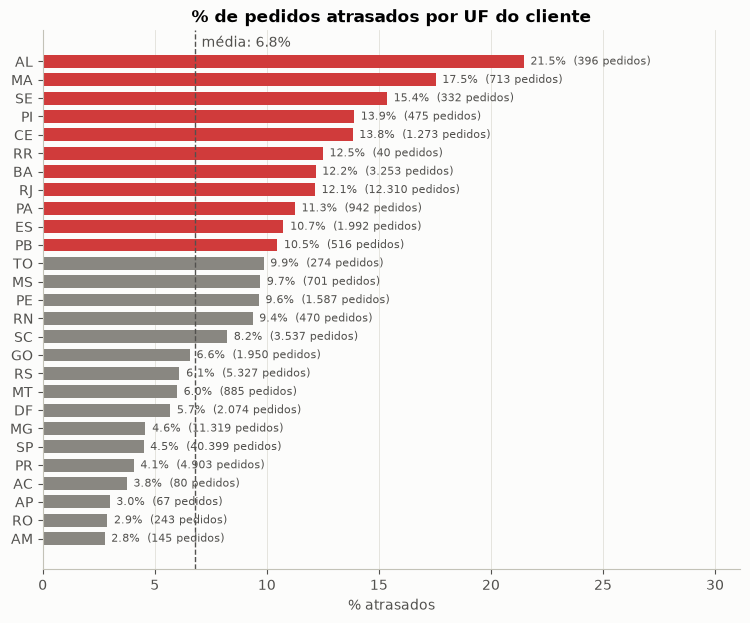

In [12]:
media_nacional = entregues['is_late'].mean() * 100
ordem = uf.sort_values('pct_atraso')

fig, ax = plt.subplots(figsize=(9, 7))
cores = np.where(ordem['pct_atraso'] > 1.5 * media_nacional, VERMELHO, CINZA)
ax.barh(ordem.index, ordem['pct_atraso'], color=cores, height=0.7)
ax.axvline(media_nacional, color=TEXTO, linestyle='--', linewidth=1)
ax.text(media_nacional + 0.3, len(ordem) - 0.2, f'média: {media_nacional:.1f}%', color=TEXTO)
for i, (valor, n) in enumerate(zip(ordem['pct_atraso'], ordem['pedidos'])):
    ax.text(valor + 0.3, i, f'{valor:.1f}%  ({n:,} pedidos)'.replace(',', '.'), va='center', fontsize=8, color=TEXTO)
ax.set(title='% de pedidos atrasados por UF do cliente', xlabel='% atrasados')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, ordem['pct_atraso'].max() * 1.45)
plt.show()

### 4.1 A promessa de prazo é calibrada da mesma forma em todo o país?

Cada ponto é uma UF. A linha tracejada é "prometido = real". Quanto mais acima da linha, maior a folga dada ao cliente. Cor: vermelho para UFs com atraso acima de 1,5× a média.

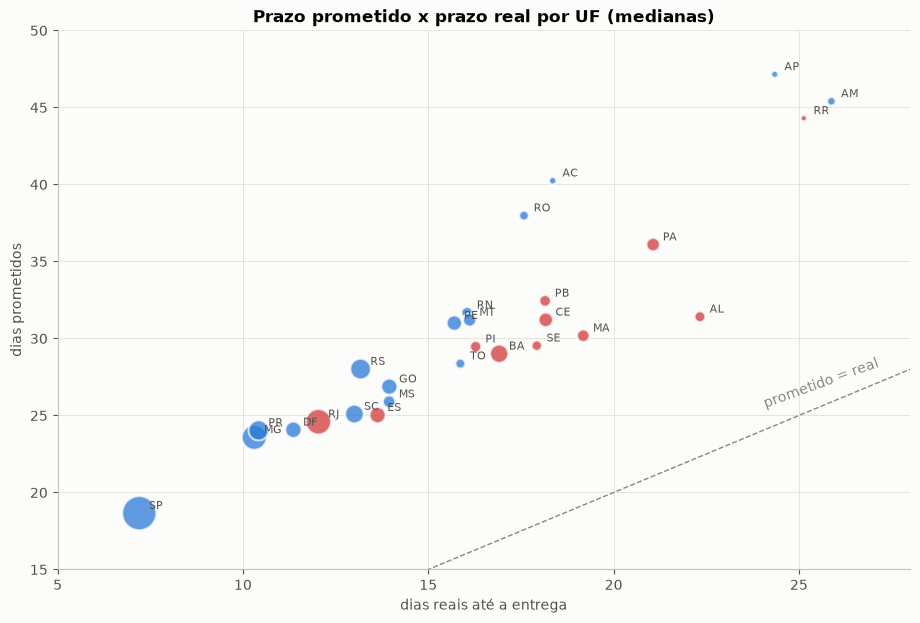

Correlação entre folga mediana e % de atraso por UF: -0.57


In [13]:
fig, ax = plt.subplots(figsize=(11, 7))
cores = np.where(uf['pct_atraso'] > 1.5 * media_nacional, VERMELHO, AZUL)
ax.scatter(uf['dias_reais'], uf['dias_prometidos'], s=np.sqrt(uf['pedidos']) * 3,
           color=cores, alpha=0.75, edgecolor='#fcfcfb', linewidth=1.5)
for sigla, linha in uf.iterrows():
    ax.annotate(sigla, (linha['dias_reais'], linha['dias_prometidos']),
                textcoords='offset points', xytext=(7, 3), fontsize=8, color=TEXTO)
ax.plot([5, 30], [5, 30], color=CINZA, linestyle='--', linewidth=1)
ax.text(24, 25.5, 'prometido = real', color=CINZA, rotation=20)
ax.set(title='Prazo prometido x prazo real por UF (medianas)',
       xlabel='dias reais até a entrega', ylabel='dias prometidos', xlim=(5, 28), ylim=(15, 50))
plt.show()

print('Correlação entre folga mediana e % de atraso por UF:',
      f"{uf['folga_mediana'].corr(uf['pct_atraso']):.2f}")

## 5. Origem do atraso: seller ou transporte?

- **Seller atrasou a postagem:** o pedido foi entregue à transportadora depois do `shipping_limit_date` combinado.
- **Rota:** seller e cliente na mesma UF ou em UFs diferentes.

In [14]:
com_postagem = entregues[entregues['order_delivered_carrier_date'].notna() & entregues['prazo_postagem'].notna()]

origem = com_postagem.groupby('seller_postou_atrasado').agg(
    pedidos=('order_id', 'size'), pct_atraso=('is_late', 'mean'), nota_media=('review_score', 'mean'))
origem['pct_pedidos'] = origem['pedidos'] / origem['pedidos'].sum() * 100
origem['pct_atraso'] *= 100
origem.index = origem.index.map({False: 'Seller postou no prazo', True: 'Seller postou atrasado'})
display(origem.round(2))

atrasados = com_postagem[com_postagem['is_late'] == 1]
pct_culpa_seller = atrasados['seller_postou_atrasado'].mean() * 100
print(f'{pct_culpa_seller:.1f}% dos pedidos atrasados começaram com postagem atrasada pelo seller.')

rota = entregues.dropna(subset=['seller_state']).groupby('mesma_uf').agg(
    pedidos=('order_id', 'size'), pct_atraso=('is_late', 'mean'),
    dias_reais=('dias_total', 'median'), frete_medio=('order_freight', 'mean'), nota_media=('review_score', 'mean'))
rota['pct_atraso'] *= 100
rota.index = rota.index.map({False: 'UFs diferentes', True: 'Mesma UF'})
display(rota.round(2))

,pedidos,pct_atraso,nota_media,pct_pedidos
seller_postou_atrasado,,,,
Seller postou no prazo,87621,5.39,4.2,91.08
Seller postou atrasado,8581,21.10,3.7,8.92


27.7% dos pedidos atrasados começaram com postagem atrasada pelo seller.


,pedidos,pct_atraso,dias_reais,frete_medio,nota_media
mesma_uf,,,,,
UFs diferentes,61598,8.07,12.78,26.91,4.10
Mesma UF,34605,4.51,6.52,15.44,4.26


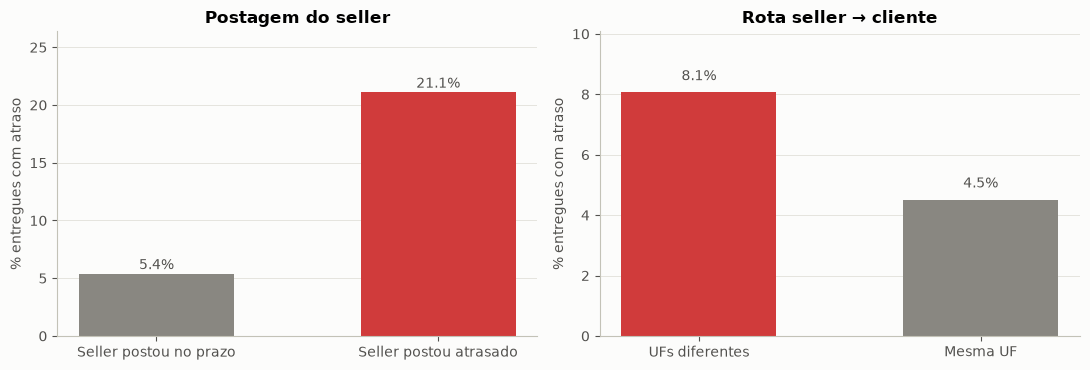

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for ax, tabela, titulo in [(axes[0], origem, 'Postagem do seller'), (axes[1], rota, 'Rota seller → cliente')]:
    cores = [CINZA, VERMELHO] if titulo.startswith('Postagem') else [VERMELHO, CINZA]
    ax.bar(tabela.index, tabela['pct_atraso'], color=cores, width=0.55)
    for i, valor in enumerate(tabela['pct_atraso']):
        ax.text(i, valor + 0.4, f'{valor:.1f}%', ha='center', color=TEXTO)
    ax.set(title=titulo, ylabel='% entregues com atraso')
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, tabela['pct_atraso'].max() * 1.25)

plt.tight_layout()
plt.show()

---
# Parte B — Pagamentos

## 6. Formas de pagamento ao longo do tempo

Pedidos entregues, pela forma de pagamento principal. Cada painel tem sua própria escala, para que as formas menores fiquem visíveis.

,% dos pedidos
forma_pagamento,
CREDIT_CARD,75.48
BOLETO,19.90
VOUCHER,3.09
DEBIT_CARD,1.54


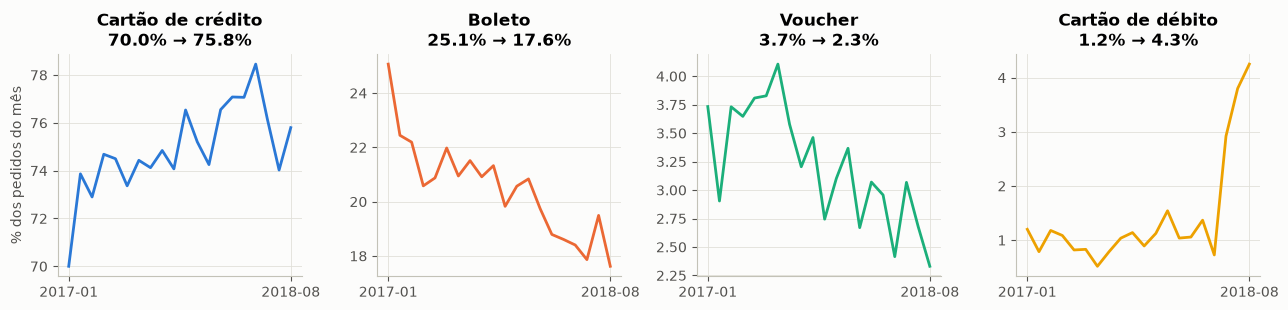

In [16]:
pag_ent = entregues.dropna(subset=['forma_pagamento'])
formas = ['CREDIT_CARD', 'BOLETO', 'VOUCHER', 'DEBIT_CARD']
nomes = {'CREDIT_CARD': 'Cartão de crédito', 'BOLETO': 'Boleto', 'VOUCHER': 'Voucher', 'DEBIT_CARD': 'Cartão de débito'}

mix = pag_ent['forma_pagamento'].value_counts(normalize=True).mul(100).rename('% dos pedidos')
display(mix.round(2).to_frame())

evolucao = (pag_ent.groupby('purchase_year_month')['forma_pagamento']
            .value_counts(normalize=True).unstack().mul(100)[formas])

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True)
for ax, forma, cor in zip(axes, formas, [AZUL, LARANJA, VERDE_AGUA, AMARELO]):
    serie = evolucao[forma]
    ax.plot(np.arange(len(serie)), serie, color=cor, linewidth=2)
    ax.set_title(f'{nomes[forma]}\n{serie.iloc[0]:.1f}% → {serie.iloc[-1]:.1f}%')
    ax.set_xticks([0, len(serie) - 1], [evolucao.index[0], evolucao.index[-1]])
axes[0].set_ylabel('% dos pedidos do mês')
plt.tight_layout()
plt.show()

## 7. Forma de pagamento x aprovação, entrega, cancelamento e nota

- Aprovação, prazo e nota: pedidos entregues.
- Cancelamento: **todos** os pedidos do período (`CANCELED` ou `UNAVAILABLE`).

In [17]:
por_forma = pag_ent[pag_ent['forma_pagamento'].isin(formas)].groupby('forma_pagamento').agg(
    pedidos=('order_id', 'size'),
    horas_aprovacao_mediana=('dias_aprovacao', lambda s: s.median() * 24),
    dias_total_mediana=('dias_total', 'median'),
    pct_atraso=('is_late', 'mean'),
    ticket_medio=('order_total', 'mean'),
    nota_media=('review_score', 'mean'),
)
por_forma['pct_atraso'] *= 100

cancel = base[base['forma_pagamento'].isin(formas)].groupby('forma_pagamento').agg(
    pedidos_total=('order_id', 'size'), pct_cancelado=('cancelado', 'mean'))
cancel['pct_cancelado'] *= 100

por_forma = por_forma.join(cancel).loc[formas].rename(index=nomes)
display(por_forma.round(2))

,pedidos,horas_aprovacao_mediana,dias_total_mediana,pct_atraso,ticket_medio,nota_media,pedidos_total,pct_cancelado
forma_pagamento,,,,,,,,
Cartão de crédito,72612,0.27,10.01,6.70,166.09,4.16,74721,1.11
Boleto,19140,29.06,11.33,7.34,144.32,4.16,19721,1.23
Voucher,2970,0.28,10.22,6.06,114.86,4.13,3123,3.04
Cartão de débito,1481,0.84,8.44,5.33,140.33,4.24,1525,0.85


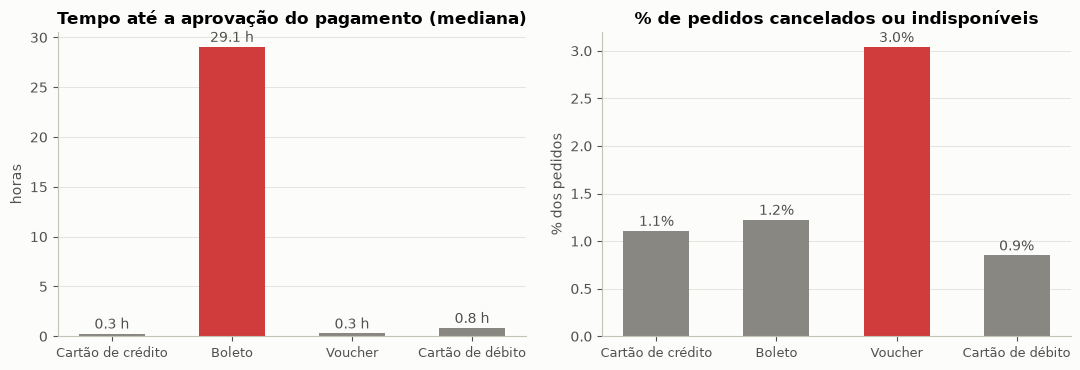

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

valores = por_forma['horas_aprovacao_mediana']
axes[0].bar(valores.index, valores, color=[CINZA, VERMELHO, CINZA, CINZA], width=0.55)
for i, v in enumerate(valores):
    axes[0].text(i, v + 0.5, f'{v:.1f} h', ha='center', color=TEXTO)
axes[0].set(title='Tempo até a aprovação do pagamento (mediana)', ylabel='horas')

valores = por_forma['pct_cancelado']
axes[1].bar(valores.index, valores, color=[CINZA, CINZA, VERMELHO, CINZA], width=0.55)
for i, v in enumerate(valores):
    axes[1].text(i, v + 0.05, f'{v:.1f}%', ha='center', color=TEXTO)
axes[1].set(title='% de pedidos cancelados ou indisponíveis', ylabel='% dos pedidos')

for ax in axes:
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.show()

## 8. Parcelamento no cartão de crédito

Faixas de parcelas iguais às da Frente 3. A coluna `% pago acima do pedido` indica pedidos em que o valor pago supera o valor do pedido em mais de R$ 1 (sinal de juros repassados ao cliente).

In [19]:
cartao = pag_ent[pag_ent['forma_pagamento'] == 'CREDIT_CARD'].copy()
cartao['faixa_parcelas'] = pd.cut(cartao['parcelas'], bins=[0, 1, 3, 6, 10, 24],
                                  labels=['1x', '2-3x', '4-6x', '7-10x', '11x+'])
cartao['pago_acima'] = (cartao['valor_pago'] - cartao['order_total']) > 1

parcelamento = cartao.groupby('faixa_parcelas', observed=True).agg(
    pedidos=('order_id', 'size'),
    ticket_medio=('order_total', 'mean'),
    nota_media=('review_score', 'mean'),
    pct_nota_baixa=('nota_baixa', 'mean'),
    pct_atraso=('is_late', 'mean'),
    pct_pago_acima_do_pedido=('pago_acima', 'mean'),
)
for coluna in ['pct_nota_baixa', 'pct_atraso', 'pct_pago_acima_do_pedido']:
    parcelamento[coluna] *= 100
display(parcelamento.round(2))

,pedidos,ticket_medio,nota_media,pct_nota_baixa,pct_atraso,pct_pago_acima_do_pedido
faixa_parcelas,,,,,,
1x,23309,100.65,4.22,11.18,5.98,0.00
2-3x,21959,134.96,4.15,12.81,6.85,0.18
4-6x,15640,181.70,4.13,13.38,6.98,0.56
7-10x,11373,333.31,4.08,15.08,7.50,0.62
11x+,329,359.32,3.93,19.15,8.21,6.99


### 8.1 Parcelamento e peso do frete por UF

Hipótese: onde o frete pesa mais no preço, o cliente paga mais caro e parcela mais.

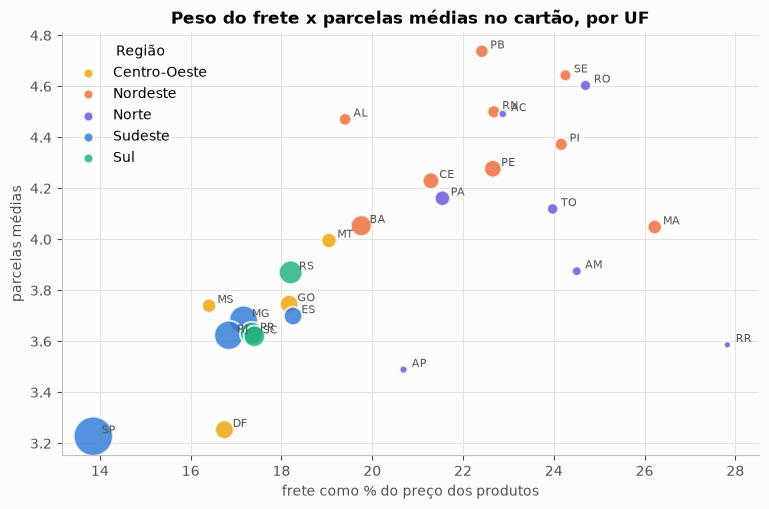

Correlação frete/preço x parcelas médias: 0.59
Correlação ticket médio x parcelas médias: 0.64


In [20]:
parcelas_uf = cartao.groupby('customer_state').agg(parcelas_medias=('parcelas', 'mean'),
                                                   ticket_medio=('order_total', 'mean'))
parcelas_uf = parcelas_uf.join(uf[['regiao', 'frete_sobre_preco_%', 'pedidos']])

fig, ax = plt.subplots(figsize=(9, 5.5))
cores_regiao = {'Sudeste': AZUL, 'Sul': VERDE_AGUA, 'Centro-Oeste': AMARELO, 'Nordeste': LARANJA, 'Norte': '#6250d6'}
for regiao, grupo in parcelas_uf.groupby('regiao'):
    ax.scatter(grupo['frete_sobre_preco_%'], grupo['parcelas_medias'], s=np.sqrt(grupo['pedidos']) * 4,
               color=cores_regiao[regiao], label=regiao, alpha=0.8, edgecolor='#fcfcfb', linewidth=1.5)
for sigla, linha in parcelas_uf.iterrows():
    ax.annotate(sigla, (linha['frete_sobre_preco_%'], linha['parcelas_medias']),
                textcoords='offset points', xytext=(6, 2), fontsize=8, color=TEXTO)
ax.set(title='Peso do frete x parcelas médias no cartão, por UF',
       xlabel='frete como % do preço dos produtos', ylabel='parcelas médias')
legenda = ax.legend(title='Região', loc='upper left')
for marcador in legenda.legend_handles:
    marcador.set_sizes([50])
plt.show()

print('Correlação frete/preço x parcelas médias:',
      f"{parcelas_uf['frete_sobre_preco_%'].corr(parcelas_uf['parcelas_medias']):.2f}")
print('Correlação ticket médio x parcelas médias:',
      f"{parcelas_uf['ticket_medio'].corr(parcelas_uf['parcelas_medias']):.2f}")

---
# Parte C — Satisfação

## 9. Nota x atraso: a partir de quando o cliente pune?

`dt_diff` = dias entre a entrega real e a prometida (negativo = antes do prazo).

,pedidos,nota_media,pct_nota_baixa
faixa_atraso,,,
15+ dias\nantes,34526,4.32,9.00
7-14 dias\nantes,40961,4.30,8.95
1-6 dias\nantes,12415,4.18,10.58
no dia,1280,4.03,12.42
1-3 dias\nde atraso,1851,3.29,32.14
4-7 dias\nde atraso,1748,2.10,67.62
8-14 dias\nde atraso,1446,1.67,80.15
15+ dias\nde atraso,1333,1.72,78.32


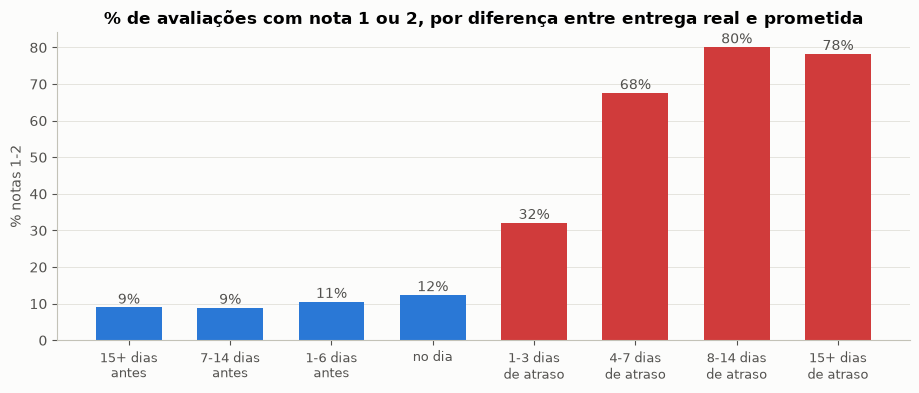

In [21]:
avaliados = entregues.dropna(subset=['review_score']).copy()
faixas = [-np.inf, -15, -7, -1, 0, 3, 7, 14, np.inf]
rotulos = ['15+ dias\nantes', '7-14 dias\nantes', '1-6 dias\nantes', 'no dia',
           '1-3 dias\nde atraso', '4-7 dias\nde atraso', '8-14 dias\nde atraso', '15+ dias\nde atraso']
avaliados['faixa_atraso'] = pd.cut(avaliados['dt_diff'], bins=faixas, labels=rotulos)

nota_atraso = avaliados.groupby('faixa_atraso', observed=True).agg(
    pedidos=('order_id', 'size'), nota_media=('review_score', 'mean'), pct_nota_baixa=('nota_baixa', 'mean'))
nota_atraso['pct_nota_baixa'] *= 100
display(nota_atraso.round(2))

fig, ax = plt.subplots(figsize=(11, 4))
cores = [AZUL] * 4 + [VERMELHO] * 4
ax.bar(nota_atraso.index.astype(str), nota_atraso['pct_nota_baixa'], color=cores, width=0.65)
for i, v in enumerate(nota_atraso['pct_nota_baixa']):
    ax.text(i, v + 1, f'{v:.0f}%', ha='center', color=TEXTO)
ax.set(title='% de avaliações com nota 1 ou 2, por diferença entre entrega real e prometida', ylabel='% notas 1-2')
ax.tick_params(axis='x', labelsize=9)
ax.grid(axis='x', visible=False)
plt.show()

### 9.1 Mesmo no prazo, demorar custa nota?

Apenas pedidos **entregues no prazo**, agrupados pelo tempo total da compra até a entrega.

,pedidos,nota_media,pct_nota_baixa
faixa_dias,,,
até 5,13357,4.45,7.13
5-10,32655,4.37,8.10
10-15,23168,4.28,9.27
15-20,11676,4.16,11.06
20-30,7414,3.99,13.70
30+,912,3.67,21.49


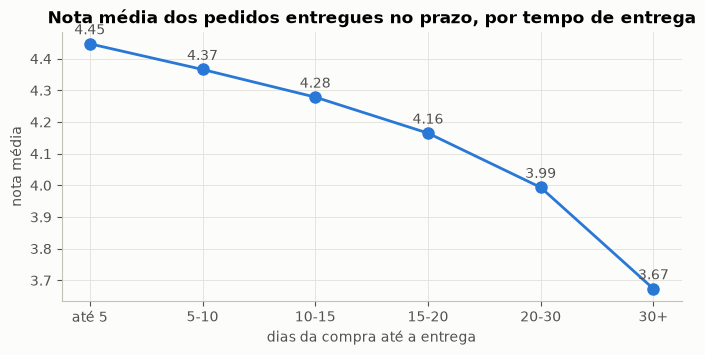

In [22]:
no_prazo = avaliados[avaliados['is_late'] == 0].copy()
no_prazo['faixa_dias'] = pd.cut(no_prazo['dias_total'], bins=[0, 5, 10, 15, 20, 30, np.inf],
                                labels=['até 5', '5-10', '10-15', '15-20', '20-30', '30+'])
nota_prazo = no_prazo.groupby('faixa_dias', observed=True).agg(
    pedidos=('order_id', 'size'), nota_media=('review_score', 'mean'), pct_nota_baixa=('nota_baixa', 'mean'))
nota_prazo['pct_nota_baixa'] *= 100
display(nota_prazo.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(nota_prazo.index.astype(str), nota_prazo['nota_media'], color=AZUL, linewidth=2, marker='o', markersize=8)
for i, v in enumerate(nota_prazo['nota_media']):
    ax.text(i, v + 0.03, f'{v:.2f}', ha='center', color=TEXTO)
ax.set(title='Nota média dos pedidos entregues no prazo, por tempo de entrega',
       xlabel='dias da compra até a entrega', ylabel='nota média')
plt.show()

## 10. Pedidos com vários itens ou vários sellers

Hipótese: quando o pedido tem produtos de sellers diferentes, os itens chegam separados e o cliente avalia antes de receber tudo.

In [23]:
avaliados['grupo_sellers'] = np.where(avaliados['qtd_sellers'] > 1, '2+ sellers', '1 seller')
avaliados['grupo_itens'] = avaliados['qtd_itens'].clip(upper=4).astype('Int64').astype(str).replace('4', '4+')

for coluna in ['grupo_sellers', 'grupo_itens']:
    tabela = avaliados.groupby(coluna).agg(
        pedidos=('order_id', 'size'), nota_media=('review_score', 'mean'),
        pct_nota_baixa=('nota_baixa', 'mean'), pct_atraso=('is_late', 'mean'))
    tabela[['pct_nota_baixa', 'pct_atraso']] *= 100
    display(tabela.round(2))

,pedidos,nota_media,pct_nota_baixa,pct_atraso
grupo_sellers,,,,
1 seller,94302,4.17,12.34,6.75
2+ sellers,1258,2.86,47.14,0.95


,pedidos,nota_media,pct_nota_baixa,pct_atraso
grupo_itens,,,,
1,86061,4.21,11.26,6.84
2,7300,3.69,25.40,5.26
3,1281,3.54,28.96,4.76
4+,918,3.36,34.10,5.01


In [24]:
import re
import unicodedata


def normalizar_texto(texto):
    texto = unicodedata.normalize('NFKD', str(texto).lower())
    return ''.join(c for c in texto if not unicodedata.combining(c))


# Comentários que falam de entrega incompleta / item faltando
padrao_incompleto = re.compile(
    r'falt|so recebi|recebi so|recebi apenas|apenas um|apenas 1|somente um|somente 1|'
    r'um dos|incomplet|nao veio|veio so|veio apenas|nao recebi o outro|ainda nao recebi|nao chegou')

comentados = avaliados[avaliados['review_comment_message'].notna()].copy()
comentados['menciona_incompleto'] = comentados['review_comment_message'].map(normalizar_texto).str.contains(padrao_incompleto)

incompleto = comentados.groupby('grupo_sellers').agg(
    comentarios=('order_id', 'size'), pct_menciona_incompleto=('menciona_incompleto', 'mean'))
incompleto['pct_menciona_incompleto'] *= 100
display(incompleto.round(2))

print('Exemplos de comentários em pedidos com 2+ sellers e nota 1:')
for texto in comentados.query("grupo_sellers == '2+ sellers' and review_score == 1 and menciona_incompleto")['review_comment_message'].head(5):
    print(' -', texto[:160])

,comentarios,pct_menciona_incompleto
grupo_sellers,,
1 seller,37849,7.25
2+ sellers,817,45.29


Exemplos de comentários em pedidos com 2+ sellers e nota 1:
 - TARGARYEN NAO ENTREGOU OS PRODUTOS COMPLETOS. NO DOIS ITENS COMPRADOS VEIO FALTANDO UNIDADES.
 - O PEDIDO, NAO CHEGOU COM A QUANTIDADE CORRETA. FALTOU O SUPORTE DE PEITO CINTA PEITORAL PARA CAMERA GOPRO GO PRO, FALTOU UM ADAPTADOR CONECTOR P2 MACHO P10 FEME
 - CHEGOU O PRODUTO ATRASADO, FALTANDO OUTRO. FALTA CHEGAR OS DEMAIS. O CLIENTE ESTA ZANGADO.
 - FOI ENTREGUE ATE O MOMENTO A MANTA. AINDA NAO RECEBI O TAPETE.
 - PEDI 5 BEST WHEY E RECEBI APENAS 3! GOSTARIA DE SABER COMO FACO PARA RECEBER OS QUE FALTARAM?


## 11. Avaliações feitas antes da entrega e pedidos não entregues

O cliente recebe o pedido de avaliação perto da data prometida. Se o produto ainda não chegou, ele avalia a falta de entrega.

In [25]:
status = base.dropna(subset=['review_score']).groupby('order_status').agg(
    pedidos_avaliados=('order_id', 'size'), nota_media=('review_score', 'mean'), pct_nota_baixa=('nota_baixa', 'mean'))
status['pct_nota_baixa'] *= 100
display(status.sort_values('pedidos_avaliados', ascending=False).round(2))

avaliados['avaliou_antes'] = avaliados['review_creation_date'] < avaliados['order_delivered_customer_date'].dt.normalize()
antes = avaliados.groupby('avaliou_antes').agg(
    pedidos=('order_id', 'size'), nota_media=('review_score', 'mean'),
    pct_nota_baixa=('nota_baixa', 'mean'), pct_atraso=('is_late', 'mean'))
antes[['pct_nota_baixa', 'pct_atraso']] *= 100
antes.index = antes.index.map({False: 'Avaliou depois de receber', True: 'Avaliou antes de receber'})
antes['% dos pedidos'] = antes['pedidos'] / antes['pedidos'].sum() * 100
display(antes.round(2))

,pedidos_avaliados,nota_media,pct_nota_baixa
order_status,,,
DELIVERED,95568,4.16,12.80
SHIPPED,1024,2.00,69.53
UNAVAILABLE,588,1.53,84.86
CANCELED,561,1.81,76.11
PROCESSING,293,1.27,92.83
INVOICED,291,1.62,82.82
CREATED,3,2.33,66.67
APPROVED,2,2.50,50.00


,pedidos,nota_media,pct_nota_baixa,pct_atraso,% dos pedidos
avaliou_antes,,,,,
Avaliou depois de receber,90600,4.28,9.51,1.80,94.81
Avaliou antes de receber,4960,1.93,72.78,95.73,5.19


## 12. Notas baixas por seller

Se poucas lojas concentram as notas 1-2 **além do que o volume delas explica**, a ação pode ser direcionada. Comparamos a concentração das notas baixas com a concentração de pedidos.

In [26]:
por_seller = avaliados.dropna(subset=['seller_id']).groupby('seller_id').agg(
    pedidos=('order_id', 'size'),
    notas_baixas=('nota_baixa', 'sum'),
    pct_nota_baixa=('nota_baixa', 'mean'),
    pct_atraso=('is_late', 'mean'),
    pct_postagem_atrasada=('seller_postou_atrasado', 'mean'),
)

pareto = por_seller.sort_values('notas_baixas', ascending=False)
pareto['pct_sellers_acum'] = np.arange(1, len(pareto) + 1) / len(pareto) * 100
pareto['pct_notas_baixas_acum'] = pareto['notas_baixas'].cumsum() / pareto['notas_baixas'].sum() * 100
pareto['pct_pedidos_acum'] = pareto['pedidos'].cumsum() / pareto['pedidos'].sum() * 100

top5 = pareto[pareto['pct_sellers_acum'] <= 5]
print(f"Sellers com pedidos avaliados: {len(pareto):,}")
print(f"Top 5% dos sellers ({len(top5)}) concentram {top5['pct_notas_baixas_acum'].iloc[-1]:.1f}% das notas baixas "
      f"e {top5['pct_pedidos_acum'].iloc[-1]:.1f}% dos pedidos.")
print('Ou seja: a concentração acompanha o volume. O sinal está na TAXA de notas baixas de cada seller.')

Sellers com pedidos avaliados: 2,930
Top 5% dos sellers (146) concentram 57.5% das notas baixas e 50.9% dos pedidos.
Ou seja: a concentração acompanha o volume. O sinal está na TAXA de notas baixas de cada seller.


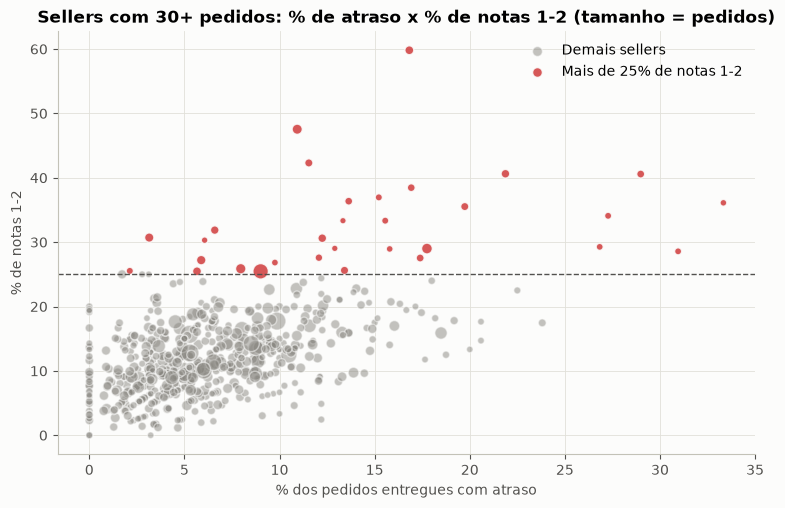

Sellers com 30+ pedidos avaliados: 615
Correlação % nota baixa x % atraso: 0.55
Correlação % nota baixa x % postagem atrasada: 0.45
Sellers críticos (mais de 25% de notas 1-2): 31, com 3,379 pedidos


,pedidos,notas_baixas,pct_nota_baixa,pct_atraso,pct_postagem_atrasada
seller_id,,,,,
7c67e1448b00f6e969d365cea6b010ab,966,246,25.5,9.0,29.6
2eb70248d66e0e3ef83659f71b244378,183,87,47.5,10.9,32.2
88460e8ebdecbfecb5f9601833981930,231,67,29.0,17.7,49.8
1ca7077d890b907f89be8c954a02686a,107,64,59.8,16.8,51.4
7040e82f899a04d1b434b795a43b4617,201,52,25.9,8.0,5.0
a49928bcdf77c55c6d6e05e09a9b4ca5,96,39,40.6,21.9,55.2
710e3548e02bc1d2831dfc4f1b5b14d4,127,39,30.7,3.1,23.6
3c7c4a49ec3c6550809089c6a2ca9370,136,37,27.2,5.9,2.2
972d0f9cf61b499a4812cf0bfa3ad3c4,78,33,42.3,11.5,33.3


In [27]:
# Sellers com volume relevante (30+ pedidos avaliados)
relevantes = por_seller[por_seller['pedidos'] >= 30].copy()

fig, ax = plt.subplots(figsize=(9, 5.5))
critico = relevantes['pct_nota_baixa'] > 0.25
ax.scatter(relevantes.loc[~critico, 'pct_atraso'] * 100, relevantes.loc[~critico, 'pct_nota_baixa'] * 100,
           s=np.sqrt(relevantes.loc[~critico, 'pedidos']) * 4, color=CINZA, alpha=0.5,
           edgecolor='#fcfcfb', linewidth=1, label='Demais sellers')
ax.scatter(relevantes.loc[critico, 'pct_atraso'] * 100, relevantes.loc[critico, 'pct_nota_baixa'] * 100,
           s=np.sqrt(relevantes.loc[critico, 'pedidos']) * 4, color=VERMELHO, alpha=0.85,
           edgecolor='#fcfcfb', linewidth=1, label='Mais de 25% de notas 1-2')
ax.axhline(25, color=TEXTO, linestyle='--', linewidth=1)
ax.set(title='Sellers com 30+ pedidos: % de atraso x % de notas 1-2 (tamanho = pedidos)',
       xlabel='% dos pedidos entregues com atraso', ylabel='% de notas 1-2')
legenda = ax.legend(loc='upper right')
for marcador in legenda.legend_handles:
    marcador.set_sizes([50])
plt.show()
print('Sellers com 30+ pedidos avaliados:', len(relevantes))
print('Correlação % nota baixa x % atraso:', f"{relevantes['pct_nota_baixa'].corr(relevantes['pct_atraso']):.2f}")
print('Correlação % nota baixa x % postagem atrasada:',
      f"{relevantes['pct_nota_baixa'].corr(relevantes['pct_postagem_atrasada']):.2f}")

criticos = relevantes[relevantes['pct_nota_baixa'] > 0.25]
print(f"Sellers críticos (mais de 25% de notas 1-2): {len(criticos)}, com {criticos['pedidos'].sum():,} pedidos")
display(criticos.sort_values('notas_baixas', ascending=False).head(10)
        .assign(pct_nota_baixa=lambda d: d['pct_nota_baixa'] * 100,
                pct_atraso=lambda d: d['pct_atraso'] * 100,
                pct_postagem_atrasada=lambda d: d['pct_postagem_atrasada'] * 100).round(1))

## 13. A satisfação traz o cliente de volta?

Para cada cliente (`customer_unique_id`), olhamos o **primeiro pedido entregue** e se ele voltou a comprar **em outro dia**. Pedidos feitos no mesmo dia da primeira compra não contam como recompra: em geral são o mesmo carrinho dividido em vários pedidos.

Consideramos só primeiras compras até fev/2018, para que todos tenham pelo menos 6 meses para voltar.

In [28]:
historico = base[base['order_status'] == 'DELIVERED'].sort_values('order_purchase_timestamp').copy()
historico['data_compra'] = historico['order_purchase_timestamp'].dt.normalize()
data_1a_compra = historico.groupby('customer_unique_id')['data_compra'].min()
historico['data_1a_compra'] = historico['customer_unique_id'].map(data_1a_compra)
historico['tipo_cliente'] = np.where(historico['data_compra'] > historico['data_1a_compra'], 'Recorrente', 'Novo')

# Primeiro retorno = primeira compra feita em um dia posterior ao da 1ª compra
retornos = historico[historico['tipo_cliente'] == 'Recorrente']
data_retorno = retornos.groupby('customer_unique_id')['order_purchase_timestamp'].min()

primeiras_todas = historico.drop_duplicates('customer_unique_id').copy()
primeiras_todas['data_retorno'] = primeiras_todas['customer_unique_id'].map(data_retorno)
primeiras_todas['dias_ate_retorno'] = (primeiras_todas['data_retorno'] - primeiras_todas['order_purchase_timestamp']).dt.days
primeiras_todas['voltou'] = primeiras_todas['data_retorno'].notna()

pedidos_no_1o_dia = historico[historico['tipo_cliente'] == 'Novo'].groupby('customer_unique_id').size()
print(f"Clientes com mais de um pedido no dia da 1ª compra: {(pedidos_no_1o_dia > 1).sum():,} "
      f"(não contam como recompra)")

primeira = primeiras_todas[primeiras_todas['order_purchase_timestamp'] < '2018-03-01'].copy()
print(f"Clientes: {len(primeira):,} | recompra: {primeira['voltou'].mean():.2%}")

for coluna, titulo in [('review_score', 'Nota da 1ª compra'), ('is_late', '1ª compra atrasou?'),
                       ('forma_pagamento', 'Forma de pagamento da 1ª compra')]:
    tabela = primeira.groupby(coluna).agg(clientes=('customer_unique_id', 'size'), pct_recompra=('voltou', 'mean'))
    tabela['pct_recompra'] *= 100
    print(titulo)
    display(tabela[tabela['clientes'] >= 100].round(2))

Clientes com mais de um pedido no dia da 1ª compra: 827 (não contam como recompra)
Clientes: 55,267 | recompra: 2.85%
Nota da 1ª compra


,clientes,pct_recompra
review_score,,
1.0,5450,2.26
2.0,1761,2.10
3.0,4790,2.51
4.0,11025,2.68
5.0,31831,3.12


1ª compra atrasou?


,clientes,pct_recompra
is_late,,
0.0,51593,2.91
1.0,3672,1.99


Forma de pagamento da 1ª compra


,clientes,pct_recompra
forma_pagamento,,
BOLETO,11553,2.71
CREDIT_CARD,41334,2.85
DEBIT_CARD,571,2.28
VOUCHER,1809,3.81


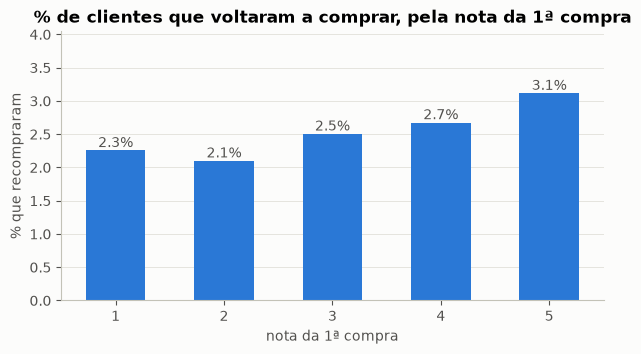

In [29]:
recompra_nota = primeira.groupby('review_score')['voltou'].mean() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(recompra_nota.index.astype(int).astype(str), recompra_nota, color=AZUL, width=0.55)
for i, v in enumerate(recompra_nota):
    ax.text(i, v + 0.05, f'{v:.1f}%', ha='center', color=TEXTO)
ax.set(title='% de clientes que voltaram a comprar, pela nota da 1ª compra',
       xlabel='nota da 1ª compra', ylabel='% que recompraram')
ax.set_ylim(0, recompra_nota.max() * 1.3)
ax.grid(axis='x', visible=False)
plt.show()

---
# Parte D — Síntese

## 14. Mapa de problemas

Tabela gerada a partir dos resultados acima (não são números fixos).

In [30]:
nota_no_prazo = avaliados.loc[avaliados['is_late'] == 0, 'review_score'].mean()
nota_atrasado = avaliados.loc[avaliados['is_late'] == 1, 'review_score'].mean()
sellers_multi = avaliados.groupby('grupo_sellers')['review_score'].mean()
ufs_criticas = uf[uf['pct_atraso'] > 1.5 * media_nacional].index.tolist()

problemas = pd.DataFrame([
    ['Logística', 'Gargalo no transporte',
     f"{lead['% do tempo total'].iloc[2]:.0f}% do tempo do pedido está entre a postagem e a entrega"],
    ['Logística', 'Crise de atraso em fev-mar/2018',
     f"Atraso chega a {mensal['pct_atraso'].max():.0f}% em {mensal['pct_atraso'].idxmax()} (média {media_nacional:.1f}%), "
     f"em todas as regiões e sem pico de volume"],
    ['Logística', 'Atraso concentrado em UFs',
     f"{len(ufs_criticas)} UFs com atraso acima de 1,5x a média: {', '.join(ufs_criticas)}"],
    ['Logística', 'Seller posta fora do prazo',
     f"{pct_culpa_seller:.0f}% dos atrasos começam com postagem atrasada do seller"],
    ['Logística', 'Promessa de prazo mal calibrada',
     f"Mediana de {entregues['folga'].median():.0f} dias de folga, mas folga desigual entre UFs"],
    ['Pagamentos', 'Boleto atrasa a aprovação',
     f"Mediana de {por_forma.loc['Boleto', 'horas_aprovacao_mediana']:.0f} h para aprovar, contra "
     f"{por_forma.loc['Cartão de crédito', 'horas_aprovacao_mediana']:.1f} h no cartão"],
    ['Pagamentos', 'Voucher com mais cancelamento',
     f"{por_forma.loc['Voucher', 'pct_cancelado']:.1f}% de cancelamento, contra "
     f"{por_forma.loc['Cartão de crédito', 'pct_cancelado']:.1f}% no cartão"],
    ['Pagamentos', 'Parcelamento longo sem juros',
     f"7 a 10x: ticket de R${parcelamento.loc['7-10x', 'ticket_medio']:.0f}; só "
     f"{parcelamento.loc['7-10x', 'pct_pago_acima_do_pedido']:.1f}% pagam acima do valor do pedido"],
    ['Satisfação', 'Atraso derruba a nota',
     f"Nota {nota_no_prazo:.2f} no prazo x {nota_atrasado:.2f} com atraso"],
    ['Satisfação', 'Pedidos com vários sellers',
     f"Nota {sellers_multi['2+ sellers']:.2f} com 2+ sellers x {sellers_multi['1 seller']:.2f} com 1 seller"],
    ['Satisfação', 'Avaliação antes de receber',
     f"{antes.loc['Avaliou antes de receber', '% dos pedidos']:.1f}% avaliam antes da entrega, "
     f"com nota {antes.loc['Avaliou antes de receber', 'nota_media']:.2f}"],
    ['Satisfação', 'Sellers críticos',
     f"{len(criticos)} sellers com mais de 25% de notas 1-2 ({criticos['pedidos'].sum():,} pedidos)".replace(',', '.')],
    ['Satisfação', 'Recompra baixa em qualquer nota',
     f"Recompra de {primeira['voltou'].mean():.1%}: {recompra_nota.loc[1]:.1f}% com nota 1 x "
     f"{recompra_nota.loc[5]:.1f}% com nota 5"],
], columns=['Frente', 'Problema', 'Evidência'])

with pd.option_context('display.max_colwidth', None):
    display(problemas)

,Frente,Problema,Evidência
0,Logística,Gargalo no transporte,74% do tempo do pedido está entre a postagem e a entrega
1,Logística,Crise de atraso em fev-mar/2018,"Atraso chega a 19% em 2018-03 (média 6.8%), em todas as regiões e sem pico de volume"
2,Logística,Atraso concentrado em UFs,"11 UFs com atraso acima de 1,5x a média: AL, MA, SE, PI, CE, RR, BA, RJ, PA, ES, PB"
3,Logística,Seller posta fora do prazo,28% dos atrasos começam com postagem atrasada do seller
4,Logística,Promessa de prazo mal calibrada,"Mediana de 12 dias de folga, mas folga desigual entre UFs"
5,Pagamentos,Boleto atrasa a aprovação,"Mediana de 29 h para aprovar, contra 0.3 h no cartão"
6,Pagamentos,Voucher com mais cancelamento,"3.0% de cancelamento, contra 1.1% no cartão"
7,Pagamentos,Parcelamento longo sem juros,7 a 10x: ticket de R$333; só 0.6% pagam acima do valor do pedido
8,Satisfação,Atraso derruba a nota,Nota 4.29 no prazo x 2.27 com atraso
9,Satisfação,Pedidos com vários sellers,Nota 2.86 com 2+ sellers x 4.17 com 1 seller


## 15. Conclusões e recomendações

### Logística

1. **O gargalo é o transporte.** Dos 12,6 dias médios entre compra e entrega, 9,4 (74%) ficam entre a postagem e a entrega. A aprovação do pagamento quase não pesa (0,4 dia).
2. **A promessa de prazo é folgada, mas desigual.** A mediana de entrega é 10 dias para uma promessa de 23, ou seja, 12 dias de folga. Mesmo assim, 6,8% dos pedidos atrasam. A folga não é a mesma no país: AM, AP, AC e RO recebem 18 a 21 dias de folga e quase não atrasam (3% a 4%), enquanto o Nordeste recebe 9 a 14 dias e lidera os atrasos (AL 21%, MA 18%, SE 15%). Quanto menor a folga da UF, maior o atraso (correlação de -0,57).
3. **Houve uma crise de atraso em fev–mar/2018** (14% e 19% de atraso, contra 6,8% de média), em todas as regiões e **sem pico de volume** (o volume foi parecido com jan e abr). A nota média caiu para 3,81. O pico de nov/2017 (12%) coincide com a Black Friday. Hipótese a validar: um evento externo nas transportadoras (a base não traz a transportadora usada).
4. **RJ é o maior problema em volume:** 12% de atraso em 12,3 mil pedidos, muito acima de SP e MG (4,5%) com distâncias parecidas.
5. **O seller também gera atraso.** Em 8,9% dos pedidos o seller postou depois do prazo combinado. Nesses casos o atraso ao cliente sobe de 5,4% para 21,1%, e 28% de todos os atrasos começam assim. Envios para outra UF atrasam quase o dobro dos envios dentro da UF (8,1% x 4,5%) e pagam frete 74% maior.

### Pagamentos

6. **O boleto atrasa a aprovação**: 29 horas de mediana, contra 0,3 hora no cartão de crédito. Isso acrescenta cerca de 1 dia à entrega (11,3 x 10,0 dias de mediana). O boleto vem perdendo espaço (25% → 18% dos pedidos), e o cartão de débito cresceu em meados de 2018 (1% → 4%).
7. **Pedidos pagos com voucher são cancelados quase 3x mais** (3,0% x 1,1% no cartão) e têm ticket menor (R$ 115). Vale investigar se há uso de cupons para testar compras ou se há falhas na validação do voucher.
8. **O parcelamento longo é praticamente sem juros para o cliente.** Na faixa de 7 a 10x (ticket de R$ 333), só 0,6% dos pedidos têm valor pago acima do pedido, então o custo financeiro fica com a operação. Essas faixas também têm mais notas baixas (15% em 7-10x e 19% em 11x+, contra 11% à vista).
9. **O frete caro empurra o parcelamento.** Nas UFs onde o frete pesa mais sobre o preço (a maioria do Norte e do Nordeste, com frete entre 19% e 28% do preço), o cliente parcela mais: até 4,7 parcelas em média na PB, contra 3,2 em SP, onde o frete é 14% do preço. Correlação de 0,59.

### Satisfação

10. **O atraso é o principal detrator, e o efeito é imediato.** No prazo, 9% a 12% de notas 1-2. Com 1 a 3 dias de atraso, 32%; com 4 a 7 dias, 68%; acima disso, cerca de 80%. Mesmo no prazo, cada faixa a mais de demora tira nota (4,45 até 5 dias → 3,99 entre 20 e 30 dias).
11. **Pedidos com mais de um seller são um problema escondido:** nota 2,86 (47% de notas 1-2) contra 4,17, embora quase nunca atrasem (1%). 45% dos comentários desses pedidos falam de item faltando ou entrega incompleta: o cliente recebe parte do pedido e avalia o que não chegou.
12. **5,2% das avaliações são feitas antes da entrega**, com nota média de 1,93. Quase todas (96%) são de pedidos atrasados: o pedido de avaliação chega na data prometida, e o cliente avalia a espera. Pedidos não entregues (enviados, cancelados ou indisponíveis) têm nota entre 1,3 e 2,0.
13. **Notas baixas: o problema é a taxa de alguns sellers, não a concentração.** O top 5% dos sellers tem 57% das notas baixas, mas também 51% dos pedidos. O sinal está nos **31 sellers com mais de 25% de notas 1-2** (3,4 mil pedidos). Nos sellers com 30+ pedidos, a taxa de notas baixas acompanha a taxa de atraso (correlação de 0,55) e a de postagem atrasada (0,45).
14. **A satisfação ajuda, mas não basta para trazer o cliente de volta.** Só 2,8% dos clientes voltaram a comprar em outro dia (todos com pelo menos 6 meses de observação): 2,3% entre quem deu nota 1 e 3,1% entre quem deu nota 5. Um atraso na primeira compra reduz a recompra de 2,9% para 2,0%. Mesmo com a melhor experiência a recompra é baixa, então o problema é estrutural (falta de incentivo para voltar). A Parte E aprofunda esse ponto.

### Recomendações (hipóteses a testar)

| # | Ação | Problemas atacados |
|---|---|---|
| 1 | **Calibrar a promessa de prazo por rota (UF do seller → UF do cliente)**, aumentando a folga no Nordeste e no RJ e reduzindo-a onde sobra (Norte, SP) | 2, 4, 10 |
| 2 | **Plano de contingência logística** para picos e crises: monitorar a taxa de atraso semanal por transportadora e acionar alternativas acima de 10% | 3 |
| 3 | **SLA de postagem para sellers**, com alerta, penalidade e menor visibilidade para quem posta atrasado; plano de ação para os 31 sellers críticos | 5, 13 |
| 4 | **Consolidar ou avisar envios separados** em pedidos com vários sellers ("seu pedido chegará em N entregas") e só pedir avaliação após a última entrega | 11 |
| 5 | **Enviar o pedido de avaliação só após a entrega confirmada**; para pedidos atrasados, enviar antes um aviso proativo com a nova data | 12 |
| 6 | **Incentivar Pix/cartão no lugar do boleto** (desconto à vista) para ganhar até 1 dia de entrega | 6 |
| 7 | **Revisar regras de voucher** e investigar o motivo dos cancelamentos | 7 |
| 8 | **Avaliar o custo do parcelamento sem juros acima de 6x** e testar frete subsidiado no Norte/Nordeste | 8, 9 |
| 9 | **Programa de recompra** (cupom pós-entrega, e-mail de recompra por categoria), já que mesmo os clientes satisfeitos raramente voltam | 14 |

**Limitações:** as comparações são descritivas e não provam causa. A base não informa a transportadora, o motivo do cancelamento nem quando cada item de um pedido com vários sellers foi entregue. Os dados de ago/2018 favorecem entregas rápidas, porque só entram pedidos já entregues.

---
# Parte E — Crescimento sustentável: fidelização e experiência de compra

> **Pergunta:** como a Olist pode transformar o crescimento das vendas em um negócio sustentável, aumentando a fidelização dos clientes e melhorando a experiência de compra?

Roteiro:
1. **Qualidade do crescimento:** de onde vem a receita (clientes novos ou recorrentes) e se ela ainda cresce.
2. **Como o cliente volta:** em quanto tempo, quanto vale e o que compra.
3. **O que a primeira experiência faz com a recompra:** prazo, atraso, nota e região.
4. **Onde há espaço para crescer:** categorias com vocação para recorrência e regiões pouco atendidas.
5. **Quanto vale melhorar:** simulação de receita.
6. **Resposta e indicadores para acompanhar.**

Definições da seção 13: cliente = `customer_unique_id`; **recorrente** = compra feita em um dia posterior ao da primeira compra.

## 16. Qualidade do crescimento: receita de clientes novos x recorrentes

In [31]:
receita_mensal = historico.pivot_table(index='purchase_year_month', columns='tipo_cliente',
                                       values='order_total', aggfunc='sum').fillna(0)
receita_mensal['Total'] = receita_mensal['Novo'] + receita_mensal['Recorrente']
receita_mensal['% recorrente'] = receita_mensal['Recorrente'] / receita_mensal['Total'] * 100
receita_mensal['clientes_novos'] = (historico[historico['tipo_cliente'] == 'Novo']
                                    .groupby('purchase_year_month')['customer_unique_id'].nunique())
display(receita_mensal.round(1))

receita_total = receita_mensal['Total'].sum()
pct_recorrente_total = receita_mensal['Recorrente'].sum() / receita_total * 100
print(f'Receita total no período: R$ {receita_total:,.2f} (validação: igual às tabelas agg_*)')
print(f'Receita de clientes recorrentes: {pct_recorrente_total:.1f}% do total')

r2018 = receita_mensal.loc['2018-01':'2018-08', 'Total']
print(f'2018: receita média de R$ {r2018.mean() / 1e6:.2f} milhão/mês, variação média mês a mês de '
      f'{r2018.pct_change().mean() * 100:+.1f}% (de R$ {r2018.min() / 1e6:.2f} a R$ {r2018.max() / 1e6:.2f} milhão)')

tipo_cliente,Novo,Recorrente,Total,% recorrente,clientes_novos
purchase_year_month,,,,,
2017-01,127313.0,169.4,127482.4,0.1,718
2017-02,270435.0,804.3,271239.3,0.3,1628
2017-03,412952.2,1378.8,414331.0,0.3,2503
2017-04,387607.5,3204.9,390812.4,0.8,2257
2017-05,558327.7,8523.7,566851.4,1.5,3451
2017-06,483014.7,7035.7,490050.4,1.4,3037
2017-07,556613.0,9686.1,566299.1,1.7,3753
2017-08,633659.2,12173.2,645832.4,1.9,4057
2017-09,686238.2,14839.3,701077.5,2.1,4005


Receita total no período: R$ 15,373,120.01 (validação: igual às tabelas agg_*)
Receita de clientes recorrentes: 2.2% do total
2018: receita média de R$ 1.06 milhão/mês, variação média mês a mês de -0.9% (de R$ 0.97 a R$ 1.13 milhão)


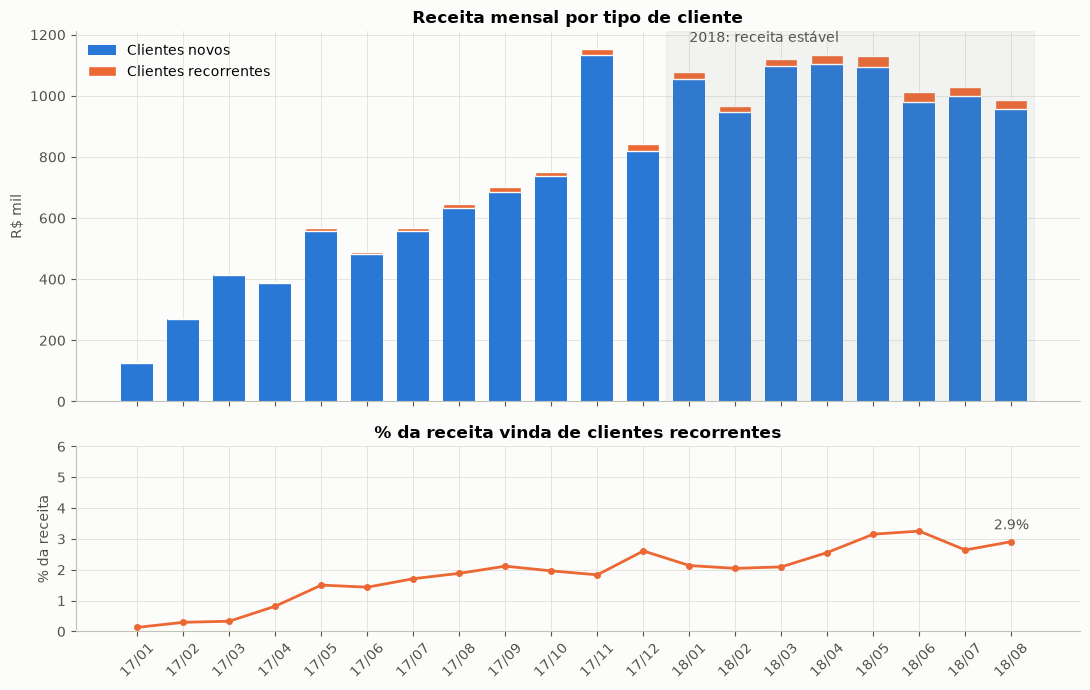

In [32]:
x = np.arange(len(receita_mensal))
meses = receita_mensal.index.str[2:].str.replace('-', '/')

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

axes[0].bar(x, receita_mensal['Novo'] / 1e3, color=AZUL, width=0.7, label='Clientes novos')
axes[0].bar(x, receita_mensal['Recorrente'] / 1e3, bottom=receita_mensal['Novo'] / 1e3,
            color=LARANJA, width=0.7, label='Clientes recorrentes', edgecolor='#fcfcfb', linewidth=1)
axes[0].axvspan(11.5, len(x) - 0.5, color=CINZA, alpha=0.08)
axes[0].text(12, receita_mensal['Total'].max() / 1e3 * 1.02, '2018: receita estável', color=TEXTO)
axes[0].set(title='Receita mensal por tipo de cliente', ylabel='R$ mil')
axes[0].legend(loc='upper left')

axes[1].plot(x, receita_mensal['% recorrente'], color=LARANJA, linewidth=2, marker='o', markersize=4)
axes[1].text(x[-1], receita_mensal['% recorrente'].iloc[-1] + 0.4,
             f"{receita_mensal['% recorrente'].iloc[-1]:.1f}%", ha='center', color=TEXTO)
axes[1].set(title='% da receita vinda de clientes recorrentes', ylabel='% da receita', ylim=(0, 6))
axes[1].set_xticks(x, meses, rotation=45)

plt.tight_layout()
plt.show()

## 17. Como o cliente volta: tempo, valor e categoria

Clientes que voltaram (todo o período): 2,005
Tempo até voltar: mediana de 73 dias | 30% em até 30 dias | 55% em até 90 dias | 76% em até 180 dias


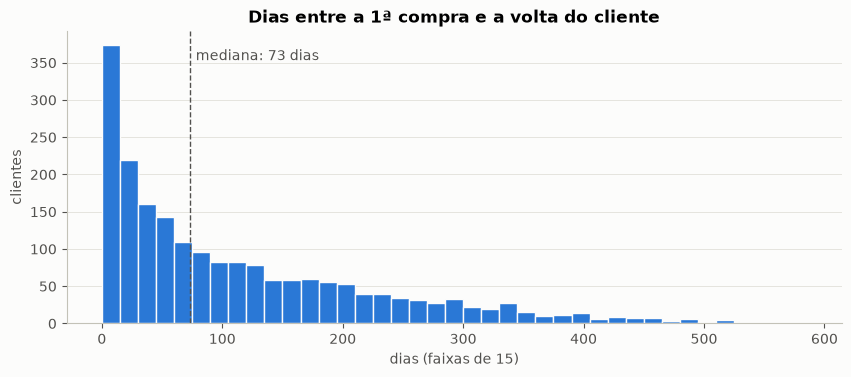

In [33]:
retornantes = primeiras_todas[primeiras_todas['voltou']]
dias_retorno = retornantes['dias_ate_retorno']

print(f'Clientes que voltaram (todo o período): {len(retornantes):,}')
print(f'Tempo até voltar: mediana de {dias_retorno.median():.0f} dias | '
      f'{(dias_retorno <= 30).mean():.0%} em até 30 dias | {(dias_retorno <= 90).mean():.0%} em até 90 dias | '
      f'{(dias_retorno <= 180).mean():.0%} em até 180 dias')

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(dias_retorno, bins=np.arange(0, dias_retorno.max() + 15, 15), color=AZUL, edgecolor='#fcfcfb', linewidth=1)
ax.axvline(dias_retorno.median(), color=TEXTO, linestyle='--', linewidth=1)
ax.text(dias_retorno.median() + 5, ax.get_ylim()[1] * 0.9, f'mediana: {dias_retorno.median():.0f} dias', color=TEXTO)
ax.set(title='Dias entre a 1ª compra e a volta do cliente', xlabel='dias (faixas de 15)', ylabel='clientes')
ax.grid(axis='x', visible=False)
plt.show()

In [34]:
por_cliente = historico.groupby('customer_unique_id').agg(
    dias_de_compra=('data_compra', 'nunique'), valor=('order_total', 'sum'))
por_cliente['perfil'] = np.where(por_cliente['dias_de_compra'] > 1, 'Voltou a comprar', 'Comprou uma vez')

valor_cliente = por_cliente.groupby('perfil').agg(clientes=('valor', 'size'), valor_medio=('valor', 'mean'),
                                                 receita=('valor', 'sum'))
valor_cliente['% clientes'] = valor_cliente['clientes'] / valor_cliente['clientes'].sum() * 100
valor_cliente['% receita'] = valor_cliente['receita'] / valor_cliente['receita'].sum() * 100
display(valor_cliente.round(2))

multiplicador = valor_cliente.loc['Voltou a comprar', 'valor_medio'] / valor_cliente.loc['Comprou uma vez', 'valor_medio']
print(f'Um cliente que volta vale {multiplicador:.1f}x o cliente de uma compra só.')

# A volta é na mesma categoria da 1ª compra?
cat_retorno = retornos.drop_duplicates('customer_unique_id').set_index('customer_unique_id')['categoria']
cat_primeira = retornantes.set_index('customer_unique_id')['categoria']
pct_mesma_categoria = (cat_primeira == cat_retorno.reindex(cat_primeira.index)).mean() * 100
print(f'{pct_mesma_categoria:.0f}% dos clientes que voltaram compraram na mesma categoria da 1ª compra.')

,clientes,valor_medio,receita,% clientes,% receita
perfil,,,,,
Comprou uma vez,91099,161.69,14729671.12,97.85,95.81
Voltou a comprar,2005,320.92,643448.89,2.15,4.19


Um cliente que volta vale 2.0x o cliente de uma compra só.
38% dos clientes que voltaram compraram na mesma categoria da 1ª compra.


## 18. O que a primeira experiência faz com a recompra

Clientes com 1ª compra até fev/2018 (pelo menos 6 meses para voltar). Mesma escala em todos os painéis.

In [35]:
primeira['faixa_entrega'] = pd.cut(primeira['dias_total'], bins=[0, 5, 10, 15, 20, 30, np.inf],
                                   labels=['até 5', '5-10', '10-15', '15-20', '20-30', '30+'])
primeira['pontualidade'] = primeira['is_late'].map({0: 'No prazo', 1: 'Atrasou'})
primeira['nota_1a'] = primeira['review_score'].astype('Int64').astype(str)

recompra_por = {}
for coluna in ['faixa_entrega', 'pontualidade', 'nota_1a', 'regiao']:
    tabela = primeira.groupby(coluna, observed=True).agg(clientes=('customer_unique_id', 'size'),
                                                         pct_recompra=('voltou', 'mean'))
    tabela['pct_recompra'] *= 100
    recompra_por[coluna] = tabela[tabela['clientes'] >= 100]

recompra_por['pontualidade'] = recompra_por['pontualidade'].loc[['No prazo', 'Atrasou']]
recompra_por['nota_1a'] = recompra_por['nota_1a'].loc[['1', '2', '3', '4', '5']]
recompra_por['regiao'] = recompra_por['regiao'].sort_values('pct_recompra', ascending=False)

for coluna, tabela in recompra_por.items():
    display(tabela.round(2))

,clientes,pct_recompra
faixa_entrega,,
até 5,5655,3.29
5-10,17176,3.16
10-15,15035,2.84
15-20,8131,2.89
20-30,6291,2.10
30+,2977,1.78


,clientes,pct_recompra
pontualidade,,
No prazo,51593,2.91
Atrasou,3672,1.99


,clientes,pct_recompra
nota_1a,,
1,5450,2.26
2,1761,2.10
3,4790,2.51
4,11025,2.68
5,31831,3.12


,clientes,pct_recompra
regiao,,
Sudeste,37251,3.05
Sul,8181,2.63
Centro-Oeste,3271,2.60
Norte,1127,2.48
Nordeste,5437,2.02


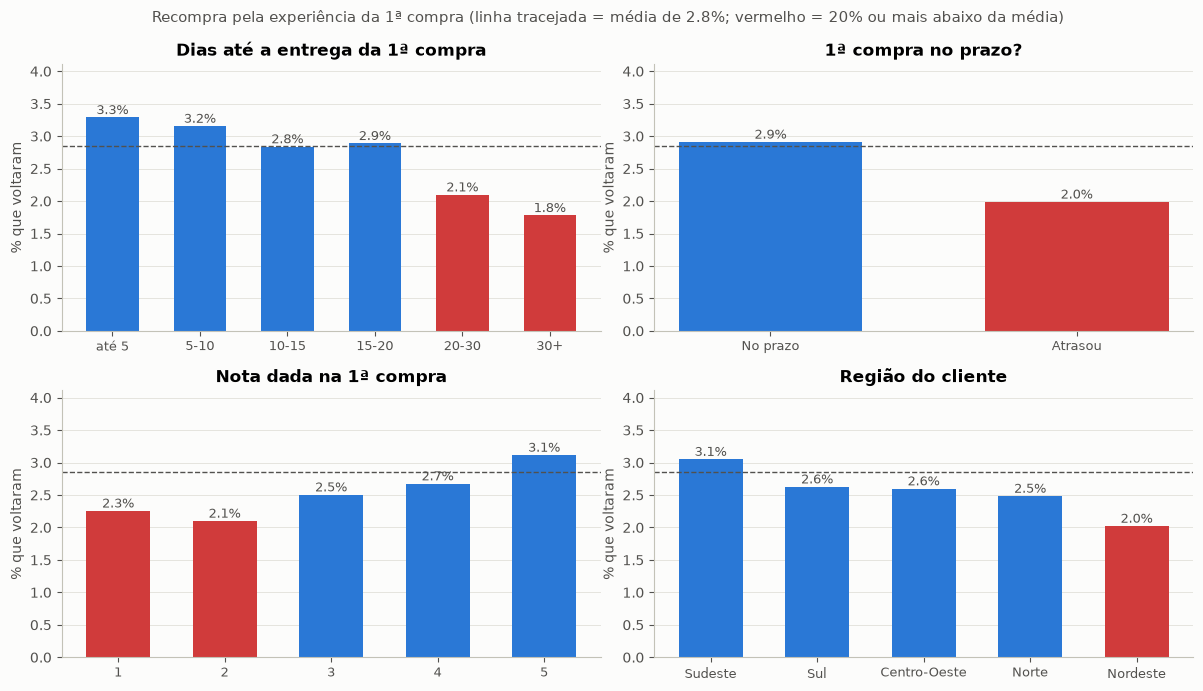

In [36]:
paineis = [('faixa_entrega', 'Dias até a entrega da 1ª compra'), ('pontualidade', '1ª compra no prazo?'),
           ('nota_1a', 'Nota dada na 1ª compra'), ('regiao', 'Região do cliente')]
taxa_geral = primeira['voltou'].mean() * 100
teto = max(t['pct_recompra'].max() for t in recompra_por.values()) * 1.25

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (coluna, titulo) in zip(axes.flat, paineis):
    tabela = recompra_por[coluna]
    cores = np.where(tabela['pct_recompra'] < taxa_geral * 0.8, VERMELHO, AZUL)
    ax.bar(tabela.index.astype(str), tabela['pct_recompra'], color=cores, width=0.6)
    for i, v in enumerate(tabela['pct_recompra']):
        ax.text(i, v + 0.05, f'{v:.1f}%', ha='center', color=TEXTO, fontsize=9)
    ax.axhline(taxa_geral, color=TEXTO, linestyle='--', linewidth=1)
    ax.set(title=titulo, ylim=(0, teto), ylabel='% que voltaram')
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelsize=9)

fig.suptitle(f'Recompra pela experiência da 1ª compra (linha tracejada = média de {taxa_geral:.1f}%; '
             'vermelho = 20% ou mais abaixo da média)', fontsize=11, color=TEXTO)
plt.tight_layout()
plt.show()

## 19. Categorias com vocação para recorrência

Categoria da 1ª compra (item de maior preço). Apenas categorias com pelo menos 500 clientes.

,clientes,pct_recompra,ticket_1a_compra
categoria,,,
FASHION_BOLSAS_E_ACESSORIOS,1130,4.87,96.94
PET_SHOP,816,4.17,147.06
MOVEIS_DECORACAO,3681,3.75,133.92
CAMA_MESA_BANHO,5368,3.74,131.32
ESPORTE_LAZER,4484,3.50,149.17
FERRAMENTAS_JARDIM,2293,3.14,160.28
PERFUMARIA,1948,2.87,142.28
BELEZA_SAUDE,4304,2.76,162.17
RELOGIOS_PRESENTES,2622,2.63,246.26


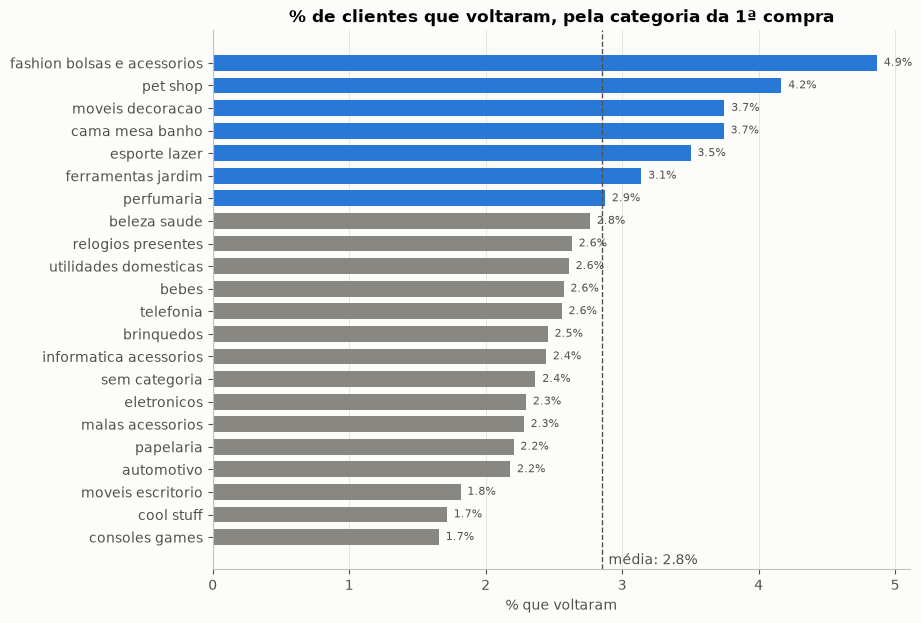

In [37]:
recompra_categoria = (primeira.groupby('categoria').agg(clientes=('customer_unique_id', 'size'),
                                                        pct_recompra=('voltou', 'mean'),
                                                        ticket_1a_compra=('order_total', 'mean'))
                      .query('clientes >= 500').sort_values('pct_recompra'))
recompra_categoria['pct_recompra'] *= 100
display(recompra_categoria.sort_values('pct_recompra', ascending=False).round(2))

fig, ax = plt.subplots(figsize=(9, 7))
cores = np.where(recompra_categoria['pct_recompra'] > taxa_geral, AZUL, CINZA)
ax.barh(recompra_categoria.index.str.replace('_', ' ').str.lower(), recompra_categoria['pct_recompra'],
        color=cores, height=0.7)
ax.axvline(taxa_geral, color=TEXTO, linestyle='--', linewidth=1)
ax.text(taxa_geral + 0.05, -1.2, f'média: {taxa_geral:.1f}%', color=TEXTO)
for i, v in enumerate(recompra_categoria['pct_recompra']):
    ax.text(v + 0.05, i, f'{v:.1f}%', va='center', fontsize=8, color=TEXTO)
ax.set(title='% de clientes que voltaram, pela categoria da 1ª compra', xlabel='% que voltaram')
ax.grid(axis='y', visible=False)
plt.show()

## 20. Onde há espaço para crescer: regiões

População por UF da tabela `analise_regional_completa.csv` (Frente 2, dados do IBGE). Pedidos, atraso, frete e recompra calculados neste notebook.

In [38]:
ibge = pd.read_csv(DATA / 'analise_regional_completa.csv').set_index('customer_state')

por_regiao = entregues.groupby('regiao').agg(pedidos=('order_id', 'size'), receita=('order_total', 'sum'),
                                             pct_atraso=('is_late', 'mean'), nota_media=('review_score', 'mean'),
                                             frete=('order_freight', 'sum'), preco=('order_price', 'sum'))
por_regiao['populacao'] = ibge['populacao_estimada'].groupby(ibge.index.map(REGIAO)).sum()
por_regiao['% população'] = por_regiao['populacao'] / por_regiao['populacao'].sum() * 100
por_regiao['% pedidos'] = por_regiao['pedidos'] / por_regiao['pedidos'].sum() * 100
por_regiao['pedidos por 100 mil hab.'] = por_regiao['pedidos'] / por_regiao['populacao'] * 1e5
por_regiao['pct_atraso'] *= 100
por_regiao['frete_sobre_preco_%'] = por_regiao['frete'] / por_regiao['preco'] * 100
por_regiao['pct_recompra'] = primeira.groupby('regiao')['voltou'].mean() * 100
por_regiao = por_regiao.drop(columns=['frete', 'preco', 'populacao']).sort_values('pedidos por 100 mil hab.', ascending=False)
display(por_regiao.round(2))

,pedidos,receita,pct_atraso,nota_media,% população,% pedidos,pedidos por 100 mil hab.,frete_sobre_preco_%,pct_recompra
regiao,,,,,,,,,
Sudeste,66020,9931792.87,6.13,4.18,41.89,68.63,77.46,15.19,3.05
Sul,13767,2230221.82,5.92,4.19,14.71,14.31,46.01,17.69,2.63
Centro-Oeste,5610,993570.00,6.54,4.13,8.00,5.83,34.45,17.59,2.60
Nordeste,9015,1816169.44,12.76,3.97,26.87,9.37,16.49,21.73,2.02
Norte,1791,399986.96,8.60,4.03,8.53,1.86,10.32,22.72,2.48


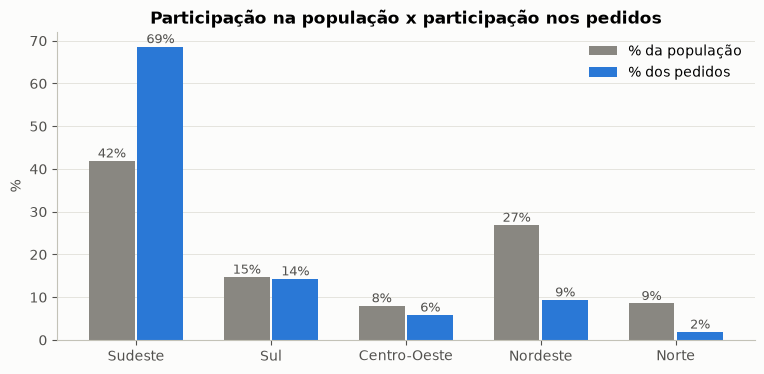

In [39]:
ordem_regioes = por_regiao.index
x = np.arange(len(ordem_regioes))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.18, por_regiao['% população'], width=0.34, color=CINZA, label='% da população')
ax.bar(x + 0.18, por_regiao['% pedidos'], width=0.34, color=AZUL, label='% dos pedidos')
for i, (p, q) in enumerate(zip(por_regiao['% população'], por_regiao['% pedidos'])):
    ax.text(i - 0.18, p + 0.8, f'{p:.0f}%', ha='center', fontsize=9, color=TEXTO)
    ax.text(i + 0.18, q + 0.8, f'{q:.0f}%', ha='center', fontsize=9, color=TEXTO)
ax.set_xticks(x, ordem_regioes)
ax.set(title='Participação na população x participação nos pedidos', ylabel='%')
ax.grid(axis='x', visible=False)
ax.legend()
plt.show()

## 21. Quanto vale melhorar: simulação de receita

Base: clientes novos e receita dos últimos 12 meses (set/2017 a ago/2018). Receita extra = clientes novos × (taxa de recompra do cenário − taxa atual) × receita média gerada por um cliente quando volta.

**Hipóteses:** os cenários de experiência supõem que a relação observada entre prazo e recompra se mantém se o prazo melhorar. Ou seja, tratam associação como efeito, o que precisa ser validado com testes. Não consideram custos (frete, cupons, marketing).

Clientes novos em 12 meses: 71,700 | receita de 12 meses: R$ 11.90 milhões
Receita média gerada por um cliente quando volta: R$ 167.29


,taxa_recompra,receita_extra_12m,% sobre a receita de 12m
Atual,2.85,0.00,0.00
Nenhuma 1ª compra atrasada,2.91,7370.10,0.06
Toda 1ª compra entregue em até 10 dias,3.19,40642.68,0.34
Programa de fidelização: 5%,5.00,257904.89,2.17
Programa de fidelização: 8%,8.00,617739.02,5.19


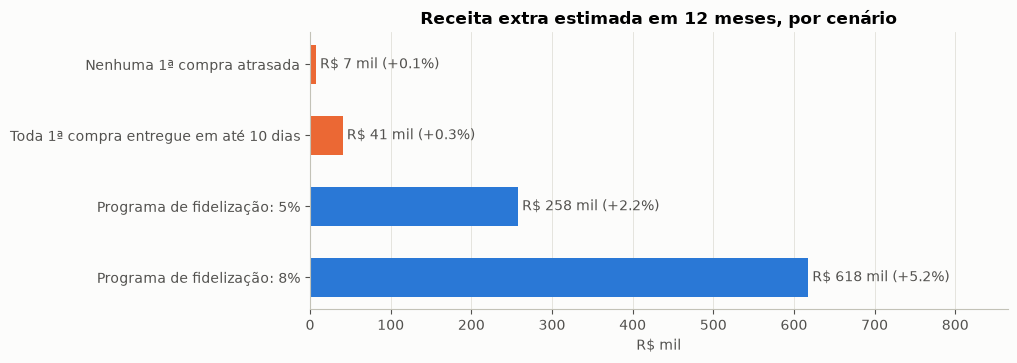

In [40]:
inicio_12m = '2017-09-01'
novos_12m = (primeiras_todas['order_purchase_timestamp'] >= inicio_12m).sum()
receita_12m = historico.loc[historico['order_purchase_timestamp'] >= inicio_12m, 'order_total'].sum()
receita_por_retorno = retornos.groupby('customer_unique_id')['order_total'].sum().mean()

taxa_atual = primeira['voltou'].mean()
cenarios = pd.Series({
    'Atual': taxa_atual,
    'Nenhuma 1ª compra atrasada': primeira.loc[primeira['is_late'] == 0, 'voltou'].mean(),
    'Toda 1ª compra entregue em até 10 dias': primeira.loc[primeira['dias_total'] <= 10, 'voltou'].mean(),
    'Programa de fidelização: 5%': 0.05,
    'Programa de fidelização: 8%': 0.08,
}, name='taxa_recompra')

simulacao = cenarios.to_frame()
simulacao['receita_extra_12m'] = novos_12m * (simulacao['taxa_recompra'] - taxa_atual) * receita_por_retorno
simulacao['% sobre a receita de 12m'] = simulacao['receita_extra_12m'] / receita_12m * 100
simulacao['taxa_recompra'] *= 100

print(f'Clientes novos em 12 meses: {novos_12m:,} | receita de 12 meses: R$ {receita_12m / 1e6:.2f} milhões')
print(f'Receita média gerada por um cliente quando volta: R$ {receita_por_retorno:.2f}')
display(simulacao.round(2))

fig, ax = plt.subplots(figsize=(9, 3.6))
dados = simulacao.drop(index='Atual')
ax.barh(dados.index[::-1], dados['receita_extra_12m'][::-1] / 1e3,
        color=[AZUL, AZUL, LARANJA, LARANJA], height=0.55)
for i, (v, pct) in enumerate(zip(dados['receita_extra_12m'][::-1] / 1e3, dados['% sobre a receita de 12m'][::-1])):
    ax.text(v + 5, i, f'R$ {v:,.0f} mil (+{pct:.1f}%)'.replace(',', '.'), va='center', color=TEXTO)
ax.set(title='Receita extra estimada em 12 meses, por cenário', xlabel='R$ mil')
ax.set_xlim(0, dados['receita_extra_12m'].max() / 1e3 * 1.4)
ax.grid(axis='y', visible=False)
plt.show()

## 22. Resposta à pergunta

### Diagnóstico: o crescimento veio de clientes novos, e esse motor parou

- **A receita parou de crescer em 2018:** cerca de R$ 1,06 milhão/mês de jan a ago, com variação média de −0,9% ao mês.
- **Quase toda a receita vem de quem compra pela primeira vez.** 97,8% dos clientes compraram uma única vez e só 2,2% da receita veio de clientes recorrentes (2,9% em ago/2018). Para crescer, a Olist precisa conquistar cerca de 6 mil clientes novos todo mês, só para repetir a receita do mês anterior.
- **O cliente que volta vale o dobro** (R$ 321 contra R$ 162), mas só 2,8% voltam. Quando voltam, levam em média 73 dias, e 55% voltam em até 90 dias.

### A experiência pesa, mas sozinha não fideliza

- **Uma experiência ruim reduz a recompra:**
  - primeira entrega em mais de 30 dias: 1,8% voltam, contra 3,3% quando chega em até 5 dias;
  - pedido atrasado: 2,0%, contra 2,9% no prazo;
  - nota 1-2: cerca de 2,2%, contra 3,1% com nota 5;
  - Nordeste: 2,0%, contra 3,1% no Sudeste.
- **Mesmo a melhor experiência só leva a cerca de 3% de recompra.** Na simulação de 12 meses:
  - zerar o atraso na primeira compra rende só cerca de R$ 7 mil a mais;
  - entregar tudo em até 10 dias rende cerca de R$ 41 mil;
  - um programa de fidelização que leve a recompra a 5% rende cerca de R$ 258 mil (+2,2% da receita); a 8%, cerca de R$ 618 mil (+5,2%).
- **Conclusão:** a experiência é a **condição necessária** (protege a nota, a reputação e a recompra que já existe), mas a **fidelização precisa de ações ativas**.

### Como transformar o crescimento em negócio sustentável: quatro frentes

**1. Entregar o que promete (0–3 meses): proteger a base**
- Calibrar o prazo prometido por rota (UF do seller → UF do cliente), com mais folga no Nordeste e no RJ.
- Criar um SLA de postagem para sellers (28% dos atrasos começam no seller) e um plano de ação para os 31 sellers críticos.
- Avisar ou consolidar entregas de pedidos com vários sellers (nota 2,86), e só pedir a avaliação depois da última entrega (5,2% avaliam antes de receber, com nota 1,93).
- Ter um plano de contingência com transportadoras para picos e crises, como a de fev–mar/2018 (19% de atraso).
- *Por quê:* com atraso, a nota cai de 4,29 para 2,27. A nota é pública e influencia quem ainda não comprou (hipótese: a base não mede conversão).

**2. Criar motivos para voltar (3–6 meses): fidelização ativa**
- Montar uma sequência de contatos após a entrega, concentrada entre **30 e 90 dias** (janela em que a maioria dos que voltam faz a 2ª compra), com cupom de segunda compra.
- Recomendar produtos da **mesma categoria** (38% voltam nela) e de categorias complementares.
- Priorizar as **categorias com mais recompra**: bolsas e acessórios (4,9%), pet shop (4,2%), móveis e decoração (3,7%), cama, mesa e banho (3,7%) e esporte e lazer (3,5%). Avaliar recompra programada em pet e cama, mesa e banho.
- Focar nos **novos clientes de alto valor** apontados pela Frente 3 (15,5% dos clientes e 28,4% da receita).
- Quem pagou a 1ª compra com voucher voltou mais (3,8%, contra 2,9% no cartão), um sinal de que cupons funcionam. Mas os pedidos com voucher são mais cancelados, então as regras precisam de controle.

**3. Crescer onde há espaço, depois de corrigir a experiência (6–12 meses)**
- O **Nordeste tem 27% da população e só 9% dos pedidos**: 16 pedidos por 100 mil habitantes, contra 77 no Sudeste. Hoje a experiência ali é pior em tudo: 12,8% de atraso, frete de 21,7% do preço, nota de 3,97 e recompra de 2,0%.
- Atrair **sellers locais** no Nordeste: entregas dentro da mesma UF atrasam quase metade (4,5% contra 8,1%) e têm frete 43% menor.
- Só depois acelerar a aquisição de clientes na região. Acelerar antes significa comprar clientes que não voltam.

**4. Cuidar da saúde financeira do crescimento**
- Reduzir a dependência de aquisição. Cada ponto percentual a mais de recompra vale cerca de R$ 120 mil por ano na base atual.
- Revisar o custo do parcelamento sem juros acima de 6x e incentivar o pagamento instantâneo no lugar do boleto (até 1 dia a menos de entrega).
- Acompanhar os indicadores da tabela abaixo mensalmente, por UF e por seller.

**Limitações:** a recompra é medida numa janela curta (6 a 20 meses), a base não traz custos de marketing nem dados de conversão, e as relações entre experiência e recompra são associações, não causa comprovada. Os ganhos estimados devem ser validados com testes A/B (por exemplo, cupom pós-entrega para metade dos novos clientes).

In [41]:
# Indicadores para acompanhar (valor atual calculado nesta análise; meta é uma sugestão)
recorte_2018 = entregues[entregues['purchase_year_month'] >= '2018-01']
indicadores = pd.DataFrame([
    ['Fidelização', '% da receita de clientes recorrentes', f'{pct_recorrente_total:.1f}%', '5% em 12 meses'],
    ['Fidelização', '% de clientes que voltam (6+ meses)', f'{taxa_atual:.1%}', '5% a 8%'],
    ['Fidelização', 'Mediana de dias até a 2ª compra', f'{dias_retorno.median():.0f} dias', 'contato ativo entre 30 e 90 dias'],
    ['Experiência', '% de pedidos entregues com atraso (2018)', f"{recorte_2018['is_late'].mean():.1%}", 'abaixo de 5% em todas as UFs'],
    ['Experiência', 'Mediana de dias até a entrega (2018)', f"{recorte_2018['dias_total'].median():.1f} dias", 'abaixo de 8 dias'],
    ['Experiência', '% de notas 1-2 (2018)', f"{recorte_2018['nota_baixa'].mean():.1%}", 'abaixo de 10%'],
    ['Experiência', '% de pedidos postados fora do prazo pelo seller', f"{entregues['seller_postou_atrasado'].mean():.1%}", 'abaixo de 5%'],
    ['Crescimento', 'Pedidos por 100 mil hab. no Nordeste', f"{por_regiao.loc['Nordeste', 'pedidos por 100 mil hab.']:.0f}",
     'crescer após corrigir o atraso na região'],
], columns=['Pilar', 'Indicador', 'Atual', 'Meta sugerida'])

with pd.option_context('display.max_colwidth', None):
    display(indicadores)

,Pilar,Indicador,Atual,Meta sugerida
0,Fidelização,% da receita de clientes recorrentes,2.2%,5% em 12 meses
1,Fidelização,% de clientes que voltam (6+ meses),2.8%,5% a 8%
2,Fidelização,Mediana de dias até a 2ª compra,73 dias,contato ativo entre 30 e 90 dias
3,Experiência,% de pedidos entregues com atraso (2018),7.7%,abaixo de 5% em todas as UFs
4,Experiência,Mediana de dias até a entrega (2018),9.5 dias,abaixo de 8 dias
5,Experiência,% de notas 1-2 (2018),13.3%,abaixo de 10%
6,Experiência,% de pedidos postados fora do prazo pelo seller,8.9%,abaixo de 5%
7,Crescimento,Pedidos por 100 mil hab. no Nordeste,16,crescer após corrigir o atraso na região
